Análise do relatório de doenças por procedência

In [1]:
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as pl #importa o pacote de plotagem
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 400
import seaborn as sns
import numpy as np
import plotly.express as px

In [2]:
df_dp = pd.read_csv('C:/Users/thami/OneDrive/Documentos/Unitoledo/Pesquisa e produtividade/dados/relatorio de doenças por procedencia.csv', 
                 sep=None,          # Let pandas detect the separator
                 engine='python',   # Use the python engine which is more flexible
                 encoding='utf-8',  # Specify encoding to handle special characters
                 on_bad_lines='warn')  # Use on_bad_lines instead of error_bad_lines
print(df_dp.head())

   MES_ANO UF_PROCEDENCIA  ESPECIE            DIAGNOSTICO  \
0  01/2003             PA  Bovinos                Bursite   
1  01/2004             RS   Suinos               Pleurite   
2  01/2005             SC     Aves             Septicemia   
3  01/2006             SP     Aves  Evisceracao Retardada   
4  01/2007             PE     Aves           Colibacilose   

   NUMERO_ANIMAIS_ACOMETIDOS  
0                        6.0  
1                       17.0  
2                      292.0  
3                       21.0  
4                       15.0  


In [3]:
#analisando o formato das colunas
df_dp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244948 entries, 0 to 244947
Data columns (total 5 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   MES_ANO                    244948 non-null  object 
 1   UF_PROCEDENCIA             244948 non-null  object 
 2   ESPECIE                    244948 non-null  object 
 3   DIAGNOSTICO                244948 non-null  object 
 4   NUMERO_ANIMAIS_ACOMETIDOS  244948 non-null  float64
dtypes: float64(1), object(4)
memory usage: 9.3+ MB


In [4]:
#analisando a estatística básica
pd.set_option('display.float_format', '{:.0f}'.format) #0f é para sem casa decimal
print(df_dp.describe())

       NUMERO_ANIMAIS_ACOMETIDOS
count                     244948
mean                       15438
std                       123208
min                            0
25%                            4
50%                           44
75%                          966
max                      5733671


In [5]:
#identificar colunas com not a number (NaN)
df_dp.isna().sum()
#identificar linhas que contenham algum not a number (NaN)
df_dp[df_dp.isna().any(axis=1)]

,MES_ANO,UF_PROCEDENCIA,ESPECIE,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS


In [6]:
#verifica a quantidade de informados 0
df_dp_0 = (df_dp == 0).sum()
print(df_dp_0)

MES_ANO                        0
UF_PROCEDENCIA                 0
ESPECIE                        0
DIAGNOSTICO                    0
NUMERO_ANIMAIS_ACOMETIDOS    371
dtype: int64


In [7]:
#analisa para encontrar linhas duplicadas
duplicate_dp = df_dp[df_dp.duplicated()]
print(duplicate_dp) #resultado sem linhas duplicadas

Empty DataFrame
Columns: [MES_ANO, UF_PROCEDENCIA, ESPECIE, DIAGNOSTICO, NUMERO_ANIMAIS_ACOMETIDOS]
Index: []


In [8]:
df_dp['NUMERO_ANIMAIS_ACOMETIDOS'] = df_dp['NUMERO_ANIMAIS_ACOMETIDOS'].astype(int)
print(df_dp.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244948 entries, 0 to 244947
Data columns (total 5 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   MES_ANO                    244948 non-null  object
 1   UF_PROCEDENCIA             244948 non-null  object
 2   ESPECIE                    244948 non-null  object
 3   DIAGNOSTICO                244948 non-null  object
 4   NUMERO_ANIMAIS_ACOMETIDOS  244948 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 9.3+ MB
None


In [9]:
df_dp.nunique()

MES_ANO                        309
UF_PROCEDENCIA                  27
ESPECIE                         46
DIAGNOSTICO                    705
NUMERO_ANIMAIS_ACOMETIDOS    33038
dtype: int64

In [10]:
df_dp.loc[:,'DIAGNOSTICO'] = df_dp['DIAGNOSTICO'].str.strip().str.lower()
print(df_dp)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
2       01/2005             SC     Aves   
3       01/2006             SP     Aves   
4       01/2007             PE     Aves   
...         ...            ...      ...   
244943  12/2025             MA   Bovino   
244944  12/2025             MG  Galinha   
244945  12/2025             PR     Peru   
244946  12/2025             RO   Bovino   
244947  12/2025             SC   Frango   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
2                                      septicemia                        292  
3                           evisceracao retardada                         21  
4                                    colibacilose                         15  
...      

In [11]:
df_dp.head()

,MES_ANO,UF_PROCEDENCIA,ESPECIE,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
0,01/2003,PA,Bovinos,bursite,6
1,01/2004,RS,Suinos,pleurite,17
2,01/2005,SC,Aves,septicemia,292
3,01/2006,SP,Aves,evisceracao retardada,21
4,01/2007,PE,Aves,colibacilose,15


In [12]:
# fica somente com a células que não tem zero no número de animais acometidos
df_dp_1 = df_dp[df_dp['NUMERO_ANIMAIS_ACOMETIDOS'] != 0]
print(df_dp_1)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
2       01/2005             SC     Aves   
3       01/2006             SP     Aves   
4       01/2007             PE     Aves   
...         ...            ...      ...   
244943  12/2025             MA   Bovino   
244944  12/2025             MG  Galinha   
244945  12/2025             PR     Peru   
244946  12/2025             RO   Bovino   
244947  12/2025             SC   Frango   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
2                                      septicemia                        292  
3                           evisceracao retardada                         21  
4                                    colibacilose                         15  
...      

In [13]:
#filtrar pelas espécies referente a pesquisa - bovinos e suínos - e padronizar os nomes
df_dp_1 = df_dp_1[df_dp_1['ESPECIE'].isin(['Bovinos', 'Suinos','Bovino','Suíno']).replace({'Bovinos': 'Bovino', 'Suinos': 'Suíno'})]
print(df_dp_1)

        MES_ANO UF_PROCEDENCIA  ESPECIE  \
0       01/2003             PA  Bovinos   
1       01/2004             RS   Suinos   
7       01/2010             ES  Bovinos   
10      01/2013             MS  Bovinos   
13      01/2014             SP  Bovinos   
...         ...            ...      ...   
244936  12/2022             MG    Suíno   
244939  12/2023             GO    Suíno   
244940  12/2023             MT   Bovino   
244943  12/2025             MA   Bovino   
244946  12/2025             RO   Bovino   

                                      DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
0                                         bursite                          6  
1                                        pleurite                         17  
7                        cisticercose calcificada                         36  
10                                       contusão                          7  
13                                       contusão                        738  
...      

In [15]:
#separa os dados por espécie
df_suino = df_dp_1[df_dp_1['ESPECIE'] == 'Suíno']
print(df_suino)

        MES_ANO UF_PROCEDENCIA ESPECIE                            DIAGNOSTICO  \
27      01/2023             PR   Suíno       aspecto repugnante (post mortem)   
31      01/2024             MS   Suíno                     lesão inflamatória   
33      01/2024             PR   Suíno       aspecto repugnante (post mortem)   
34      01/2024             SC   Suíno     linfadenite granulomatosa (suínos)   
37      01/2025             PR   Suíno      erisipela suína (notificação sif)   
...         ...            ...     ...                                    ...   
244902  11/2022             RJ   Suíno                     alteração restrita   
244934  12/2021             SP   Suíno      erisipela suína (notificação sif)   
244935  12/2021             SP   Suíno                         esplenomegalia   
244936  12/2022             MG   Suíno  linfadenite caseosa (notificação sif)   
244939  12/2023             GO   Suíno                 prolapso (ante mortem)   

        NUMERO_ANIMAIS_ACOM

In [16]:
df_suino['DIAGNOSTICO'].unique()

array(['aspecto repugnante (post mortem)', 'lesão inflamatória',
       'linfadenite granulomatosa (suínos)',
       'erisipela suína (notificação sif)', 'abscesso (mamíferos)',
       'hérnia (detectada no ante mortem)', 'parasitose não zoonótica',
       'artrite (mais de uma articulação)', 'lesão de pele',
       'alterações musculares (rigidez atípica)', 'lesão traumática',
       'pneumonia enzoótica suínos', 'aderência de pleura (seca)',
       'canibalismo (no ante mortem)', 'aderência de pleura (úmida)',
       'falha tecnológica', 'magreza', 'miíase cutânea',
       'alteração restrita', 'contaminação gastrointestinal e biliar',
       'gordura amarela', 'morto (no transporte)',
       'fratura (após a morte)', 'criptorquida (suíno)',
       'alteração linfática inespecífica',
       'coloração anormal (post mortem)',
       'lesão traumática (detectada no ante mortem)', 'septicemia',
       'hipertermia (detectada no ante mortem)',
       'contaminação não gastrointestinal',


In [17]:
#Retira as doenças que não são de interesse para a pesquisa utilizando o método isin() para filtrar as linhas que não correspondem às doenças listadas. O operador ~ é usado para negar a condição, ou seja, para selecionar as linhas que não estão na lista de doenças.
df_suino_doenças = df_suino[~df_suino['DIAGNOSTICO'].isin(['aborto enzoótico das ovelhas (confirmado)','abscesso subcutâneo (lagomorfos)','adenomatose pulmonar ovina (notificação sif)','aerossaculite (aves)','aerossaculite (condenação total autocontrole)',
                                                           'anemia infecciosa equina (confirmado)','arterite viral equina (confirmado)','arterite viral equina (suspeito)','artrite viral aves (já notificado)',
                                                           'artrite viral aves (notificação sif)','babesiose bovina (notificação sif)','celulite (aves)',
                                                           'cisticercose bovina','colibacilose aves (já notificado)','encefalomielite equina do leste (confirmado)','metrite contagiosa equina (confirmado)',
                                                           'metrite contagiosa equina (suspeito)','septicemia hemorrágica bovina (já notificado)','septicemia hemorrágica bovina (notificação sif)',
                                                           'síndrome ascítica (aves)'
])].sort_values(by='NUMERO_ANIMAIS_ACOMETIDOS', ascending=True)
print(df_suino_doenças)

        MES_ANO UF_PROCEDENCIA ESPECIE  \
41629   08/2024             MG   Suíno   
158373  02/2026             SP   Suíno   
158394  03/2021             SC   Suíno   
45041   11/2021             MT   Suíno   
158396  03/2022             DF   Suíno   
...         ...            ...     ...   
29078   06/2022             SC   Suíno   
126006  09/2021             SC   Suíno   
13138   11/2021             SC   Suíno   
194569  05/2022             SC   Suíno   
187189  03/2022             SC   Suíno   

                                        DIAGNOSTICO  NUMERO_ANIMAIS_ACOMETIDOS  
41629                                      caquexia                          1  
158373            erisipela suína (notificação sif)                          1  
158394                                     enterite                          1  
45041                                fígado amarelo                          1  
158396  lesão traumática (detectada no ante mortem)                          1  
...      

In [ ]:
df_suino_doenças_infecto = df_suino_doenças[df_suino_doenças['DIAGNOSTICO'].isin(['abscesso','abscesso (mamíferos)','acrobustite','actinobacilose','actinobacilose (ruminantes)',
                                                           'actinomicose (já notificado)','actinomicose (notificação sif)','adenite','agalaxia contagiosa (já notificado)',
                                                           'agalaxia contagiosa (notificação sif)','botulismo (notificação sif)','broncopneumonia',
                                                           'bronquite','brucella abortus (já notificado)','brucella abortus (notificação sif)','brucella melitensis (confirmado)',
                                                           'brucella melitensis (suspeito)','brucelose','brucelose (reagentes já notificados)','brucelose (reagentes notificação sif)',
                                                           'bursite','carbúnculo hemático (suspeito)','carbúnculo sintomático (notificação sif)','clostridiose (notificação sif)',
                                                           'endocardite','enterotoxemia (notificação sif)','estomatite','estomatite vesicular (confirmado)','footrot (já notificado)',
                                                           'footrot (notificação sif)','lesões tuberculósicas','leucose aviária (notificação sif)','leucose bovina','leucose enzoótica bovina (já notificado)',
                                                           'leucose enzoótica bovina (notificação sif)','linfadenite','linfadenite caseosa (já notificado)','linfadenite caseosa (notificação sif)','linfadenite granulomatosa (suínos)',
                                                           'listeriose (já notificado)','mastite aguda','necrobacilose','papilomatose','paratuberculose (já notificado)','paratuberculose (notificação sif)','pleuropneumonia contagiosa',
                                                           'pleuropneumonia contagiosa bovina (confirmado)','pleuropneumonia contagiosa bovina (suspeito)','pneumoenterite','pneumonia','pneumonia enzoótica (já notificado)',
                                                           'pneumonia enzoótica (notificação sif)','pododermite','prevenção de e.e.b.','raiva bovina (confirmado)','septicemia','septicemia hemorrágica bovina (já notificado)',
                                                           'septicemia hemorrágica bovina (notificação sif)','síndrome hemorrágica (suspeito)','síndrome nervosa (suspeito)','tétano (notificação sif)','tuberculose',
                                                           'tuberculose (já notificado)','tuberculose (notificação sif)','tuberculose (reagente já notificado)','tuberculose (reagente notificação sif)','tuberculose aviária (notificação sif)',
                                                           'tuberculose calcificada','tuberculose caseosa','tuberculose miliar','variola','varíola bovina (já notificado)'
])].sort_values(by='NUMERO_ANIMAIS_ACOMETIDOS', ascending=False)
print(df_suino_doenças_infecto)

        MES_ANO UF_PROCEDENCIA ESPECIE                     DIAGNOSTICO  \
71752   10/2021             TO  Bovino            abscesso (mamíferos)   
66057   08/2022             TO  Bovino            abscesso (mamíferos)   
122166  09/2022             TO  Bovino            abscesso (mamíferos)   
131902  11/2023             TO  Bovino            abscesso (mamíferos)   
197533  09/2023             TO  Bovino            abscesso (mamíferos)   
...         ...            ...     ...                             ...   
30210   10/2021             AC  Bovino   tuberculose (notificação sif)   
30177   09/2025             MS  Bovino                      septicemia   
229118  08/2023             AC  Bovino           lesões tuberculósicas   
30132   08/2022             MT  Bovino  actinomicose (notificação sif)   
244946  12/2025             RO  Bovino                      septicemia   

        NUMERO_ANIMAIS_ACOMETIDOS  
71752                        5817  
66057                        5264  
122

In [18]:
df_suino_doenças.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23242 entries, 41629 to 187189
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   MES_ANO                    23242 non-null  object
 1   UF_PROCEDENCIA             23242 non-null  object
 2   ESPECIE                    23242 non-null  object
 3   DIAGNOSTICO                23242 non-null  object
 4   NUMERO_ANIMAIS_ACOMETIDOS  23242 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.1+ MB


In [19]:
df_suino_doenças.describe()

,NUMERO_ANIMAIS_ACOMETIDOS
count,23242
mean,3571
std,19253
min,1
25%,5
50%,32
75%,316
max,327643


In [20]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_suino_doenças_max = df_suino_doenças[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].max()
print(df_suino_doenças_max)

UF_PROCEDENCIA                              TO
DIAGNOSTICO                  útero com feto(s)
NUMERO_ANIMAIS_ACOMETIDOS               327643
dtype: object


In [21]:
#CONFERINDO O VALOR MÁXIMO DO DESCRIBE
df_suino_doenças_min = df_suino_doenças[['UF_PROCEDENCIA','DIAGNOSTICO','NUMERO_ANIMAIS_ACOMETIDOS']].min()
print(df_suino_doenças_min)

UF_PROCEDENCIA                                   AC
DIAGNOSTICO                  aborto recente (fêmea)
NUMERO_ANIMAIS_ACOMETIDOS                         1
dtype: object


INÍCIO DA ESTATÍSTICA DESCRITIVA

In [22]:
#adequando o formato da coluna de data para extrair o ano
df_suino_doenças["MES_ANO"] = pd.to_datetime(df_suino_doenças["MES_ANO"], format="%m/%Y", errors='coerce')
df_suino_doenças["ANO"] = df_suino_doenças["MES_ANO"].dt.year
print(df_suino_doenças.head())

          MES_ANO UF_PROCEDENCIA ESPECIE  \
41629  2024-08-01             MG   Suíno   
158373 2026-02-01             SP   Suíno   
158394 2021-03-01             SC   Suíno   
45041  2021-11-01             MT   Suíno   
158396 2022-03-01             DF   Suíno   

                                        DIAGNOSTICO  \
41629                                      caquexia   
158373            erisipela suína (notificação sif)   
158394                                     enterite   
45041                                fígado amarelo   
158396  lesão traumática (detectada no ante mortem)   

        NUMERO_ANIMAIS_ACOMETIDOS   ANO  
41629                           1  2024  
158373                          1  2026  
158394                          1  2021  
45041                           1  2021  
158396                          1  2022  


In [23]:
#Realizando o resumo por ano, estado de procedência e diagnóstico
variaveis = ["ANO","UF_PROCEDENCIA", "DIAGNOSTICO"]

for var in variaveis:
    resumo = (
        df_suino_doenças.groupby(var, as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
          .sum()
          .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
    )
    
    resumo["percentual"] = (
        resumo["NUMERO_ANIMAIS_ACOMETIDOS"] / resumo["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
    )
    
    print(f"\nResumo por {var}")
    display(resumo.head(20))


Resumo por ANO


,ANO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
1,2022,18657400,22
2,2023,16067166,19
4,2025,15414173,19
3,2024,14883740,18
0,2021,14699785,18
5,2026,3284070,4



Resumo por UF_PROCEDENCIA


,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
22,SC,23499489,28
16,PR,19793695,24
21,RS,18849001,23
7,GO,5875808,7
9,MG,5119785,6
10,MS,4388317,5
11,MT,3559044,4
24,SP,1631317,2
0,AC,116201,0
5,DF,105868,0



Resumo por DIAGNOSTICO


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
11,alteração restrita,41599696,50
44,contaminação gastrointestinal e biliar,22849185,28
45,contaminação não gastrointestinal,4684108,6
6,aderência de pleura (seca),2534376,3
142,sêneca vírus (confirmado),2072571,2
73,falha tecnológica,1970149,2
95,lesão inflamatória,1391024,2
77,fratura (após a morte),1323698,2
105,linfadenite granulomatosa (suínos),1058153,1
2,abscesso (mamíferos),512043,1


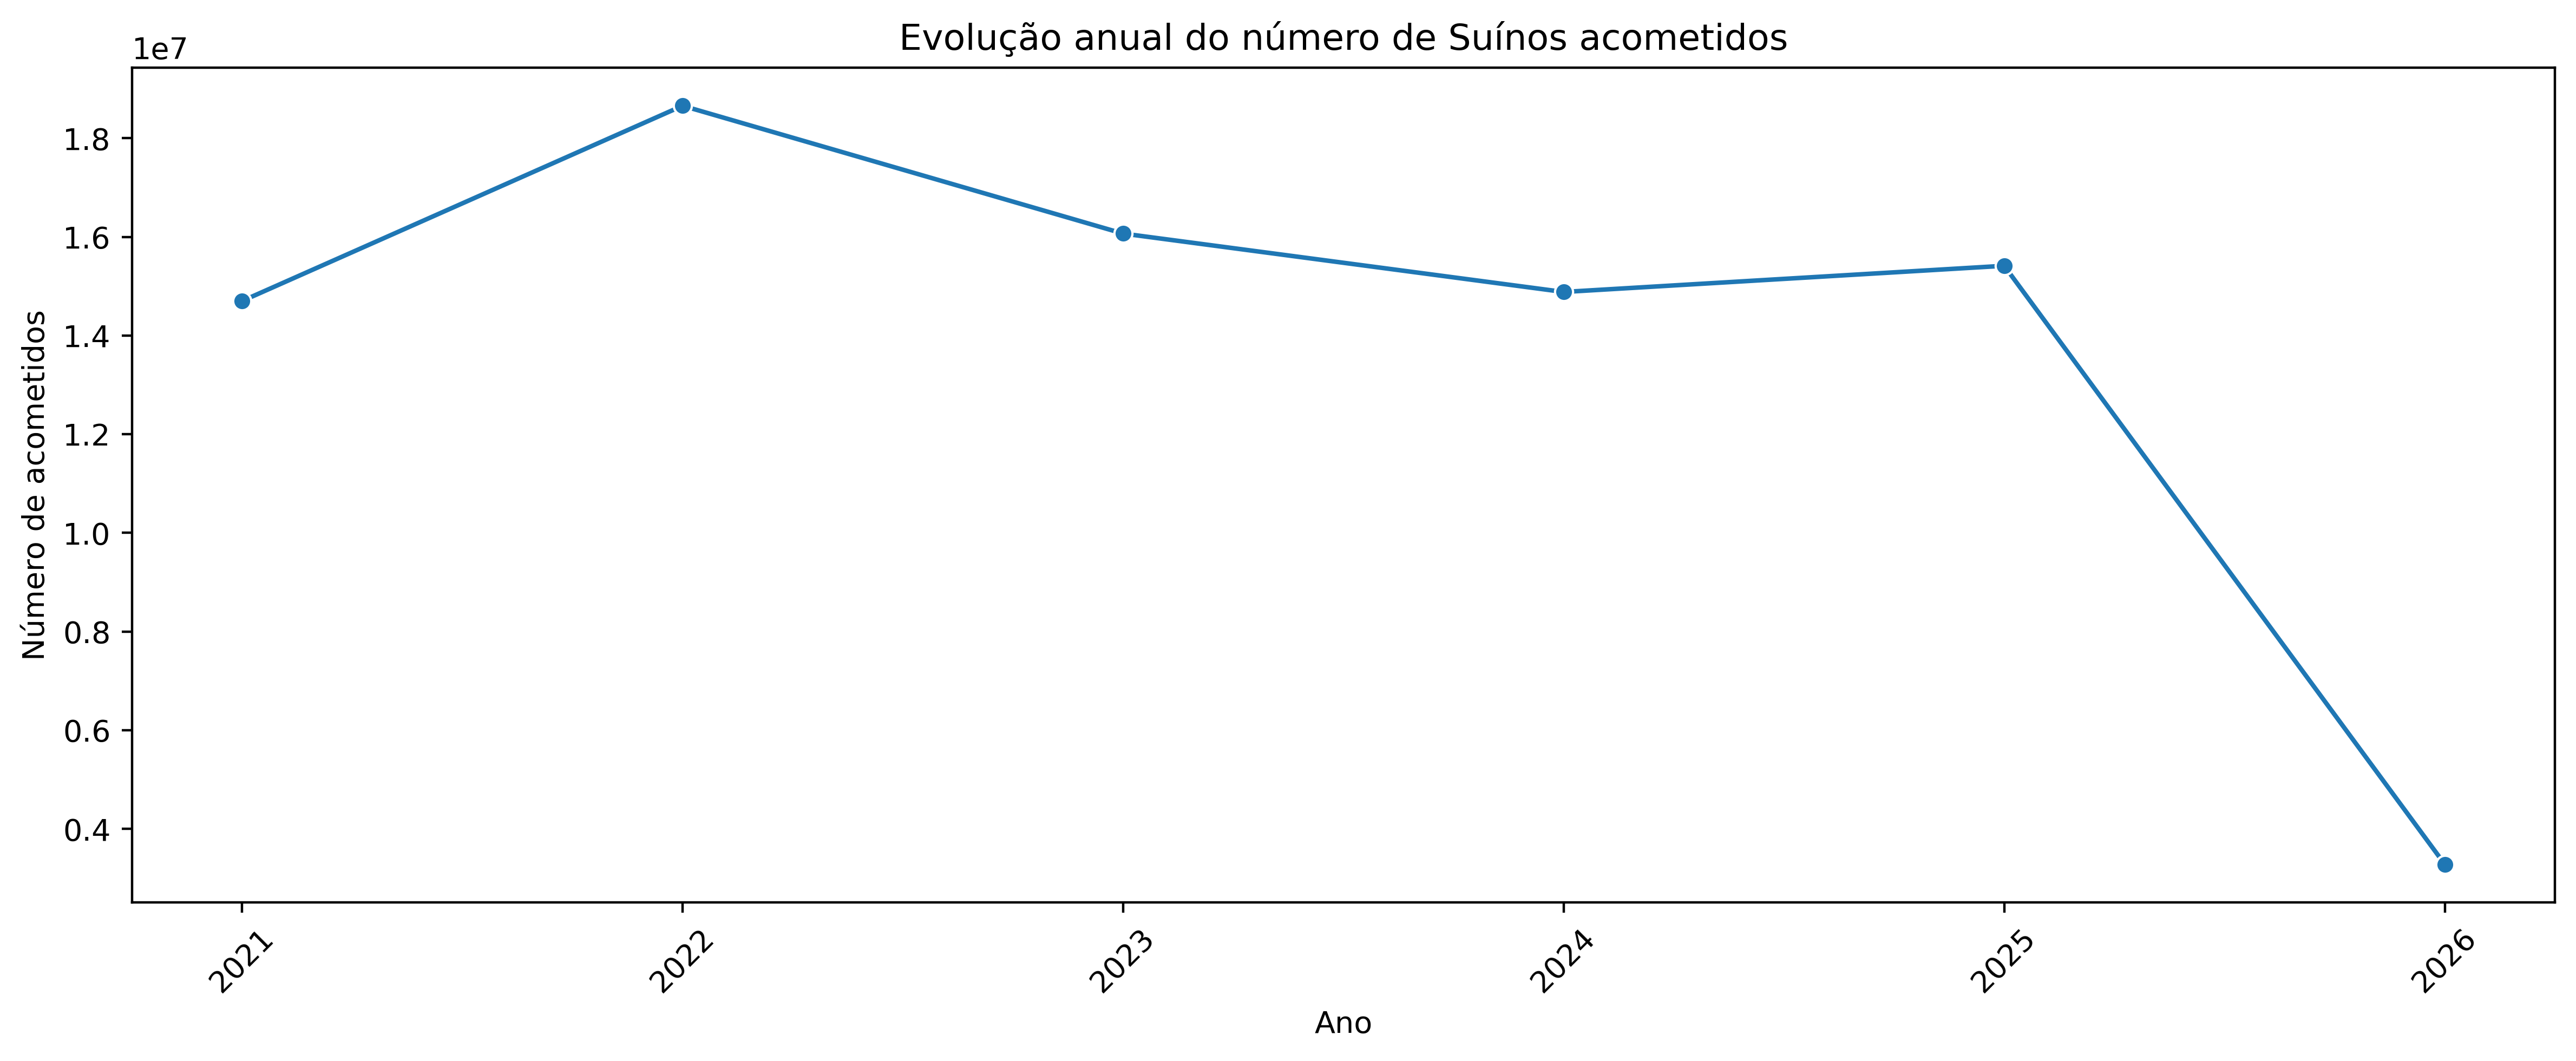

In [24]:
#criando a série anual do número de acometidos por ano
serie_anual = (
   df_suino_doenças.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
)

pl.figure(figsize=(12, 5))
sns.lineplot(
    data=serie_anual,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    marker="o"
)

pl.title("Evolução anual do número de Suínos acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(rotation=45)
pl.tight_layout()
pl.show()

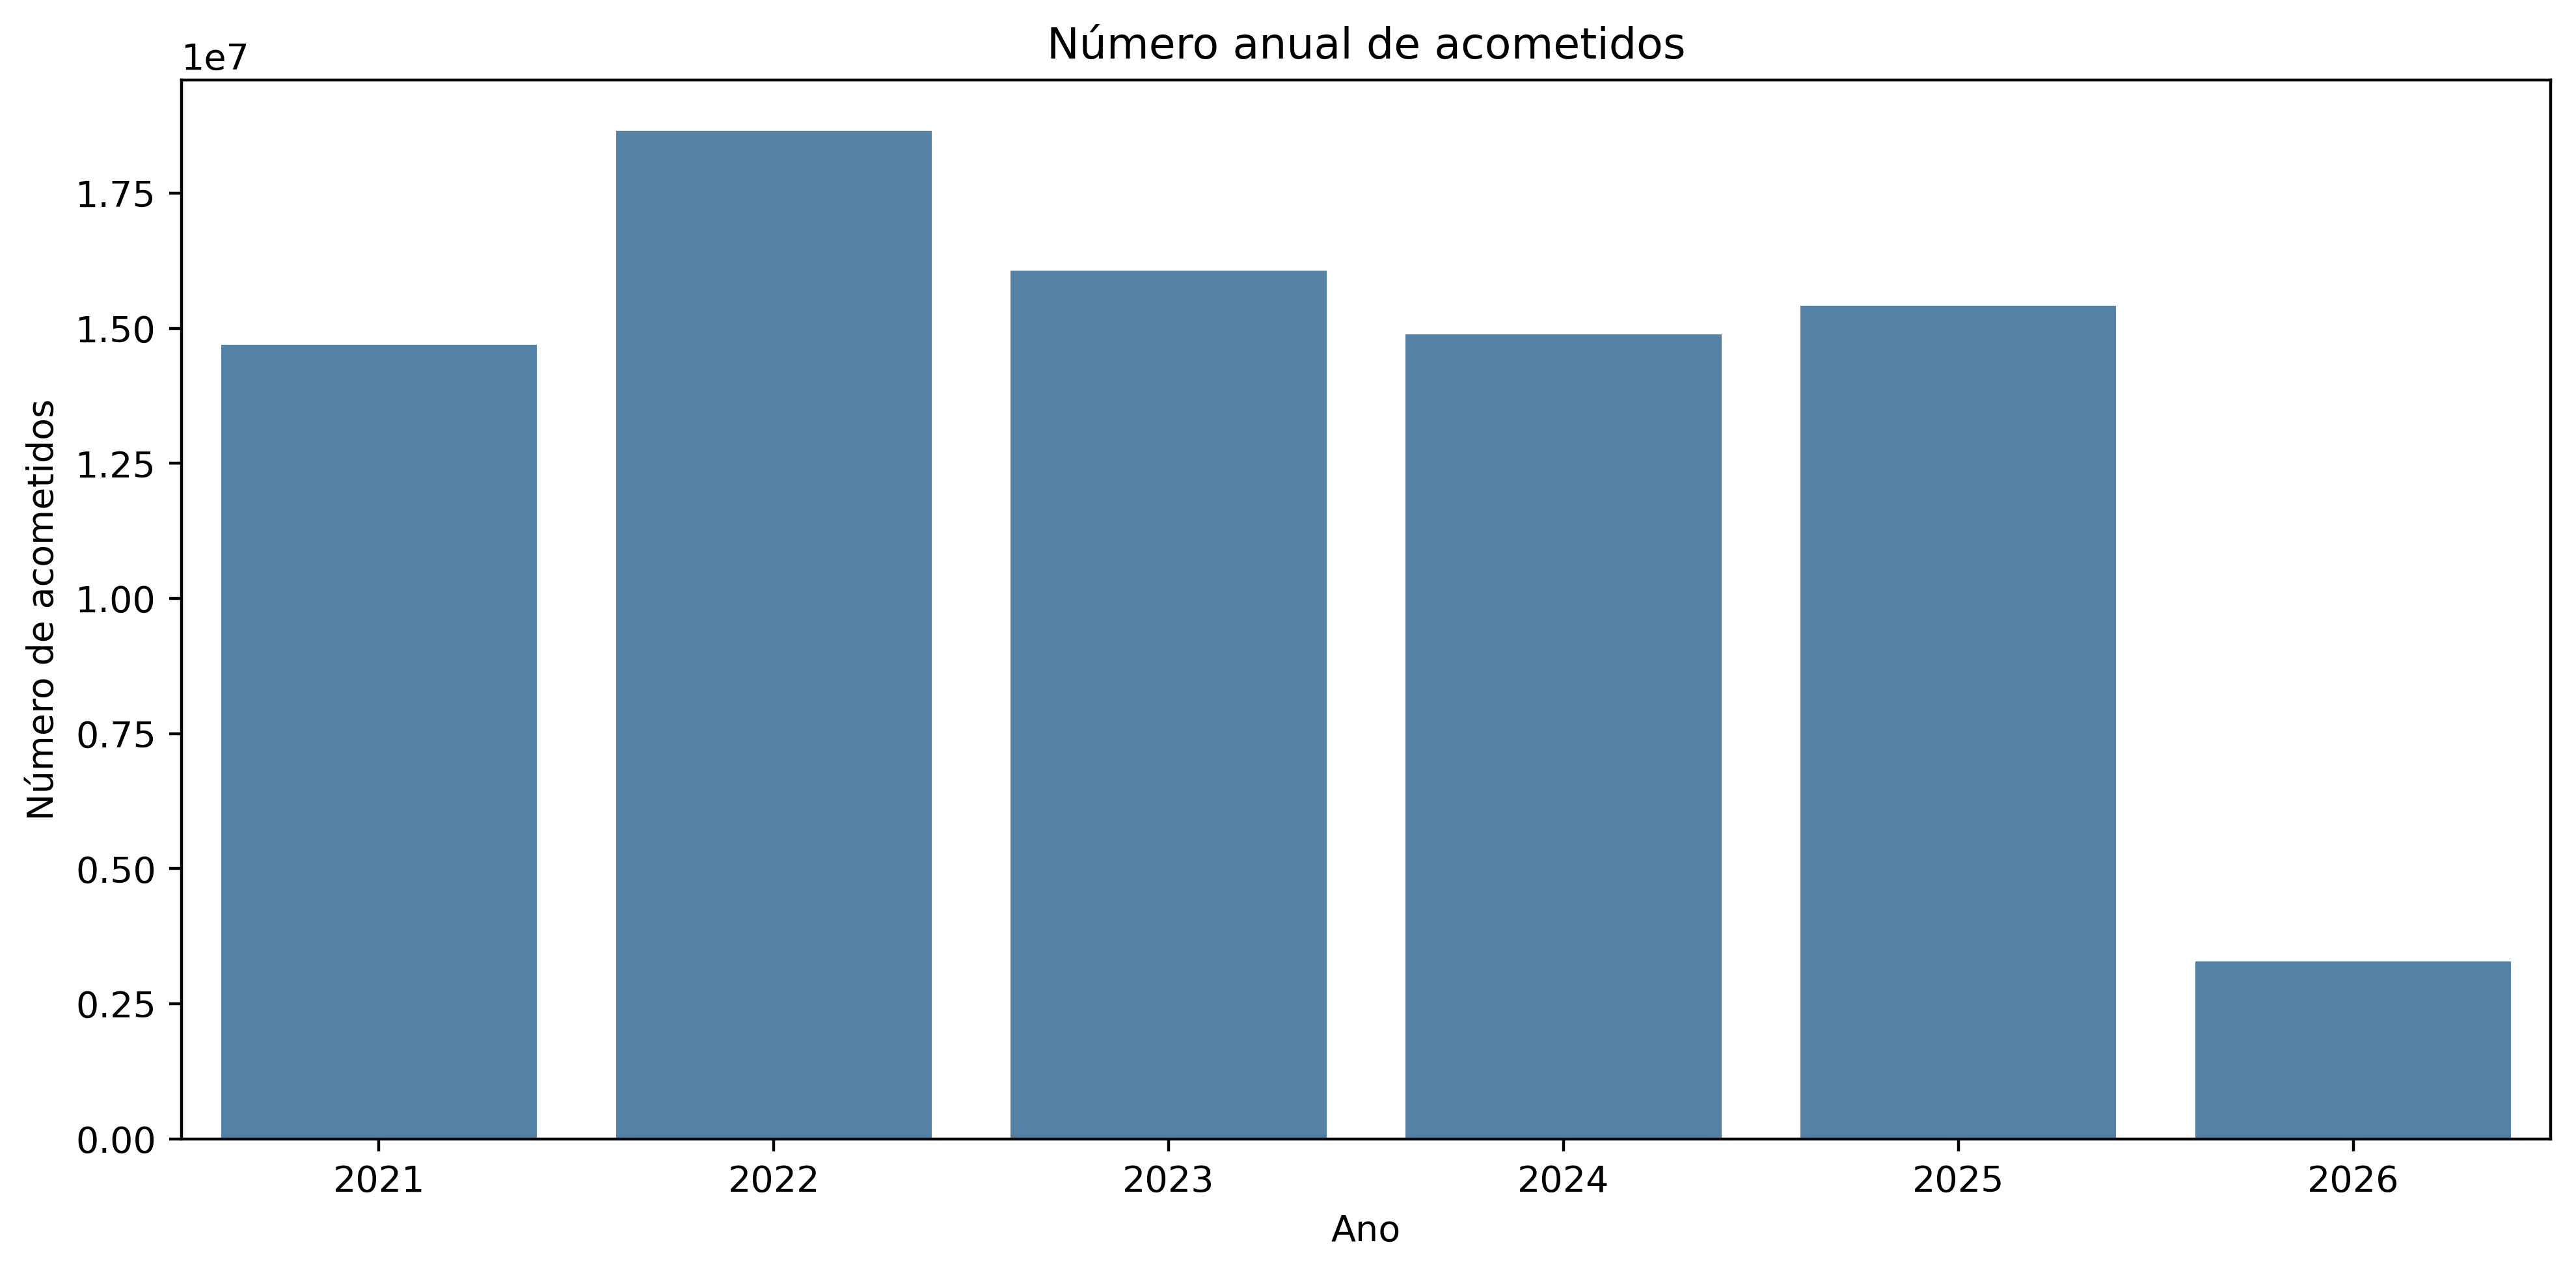

In [25]:
#criando o gráfico de barras do número anual de acometidos
pl.figure(figsize=(10, 5))

sns.barplot(
    data = (
    df_suino_doenças.groupby("ANO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("ANO")
                        ),
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    color="steelblue"
)

pl.title("Número anual de acometidos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.tight_layout()
pl.show()

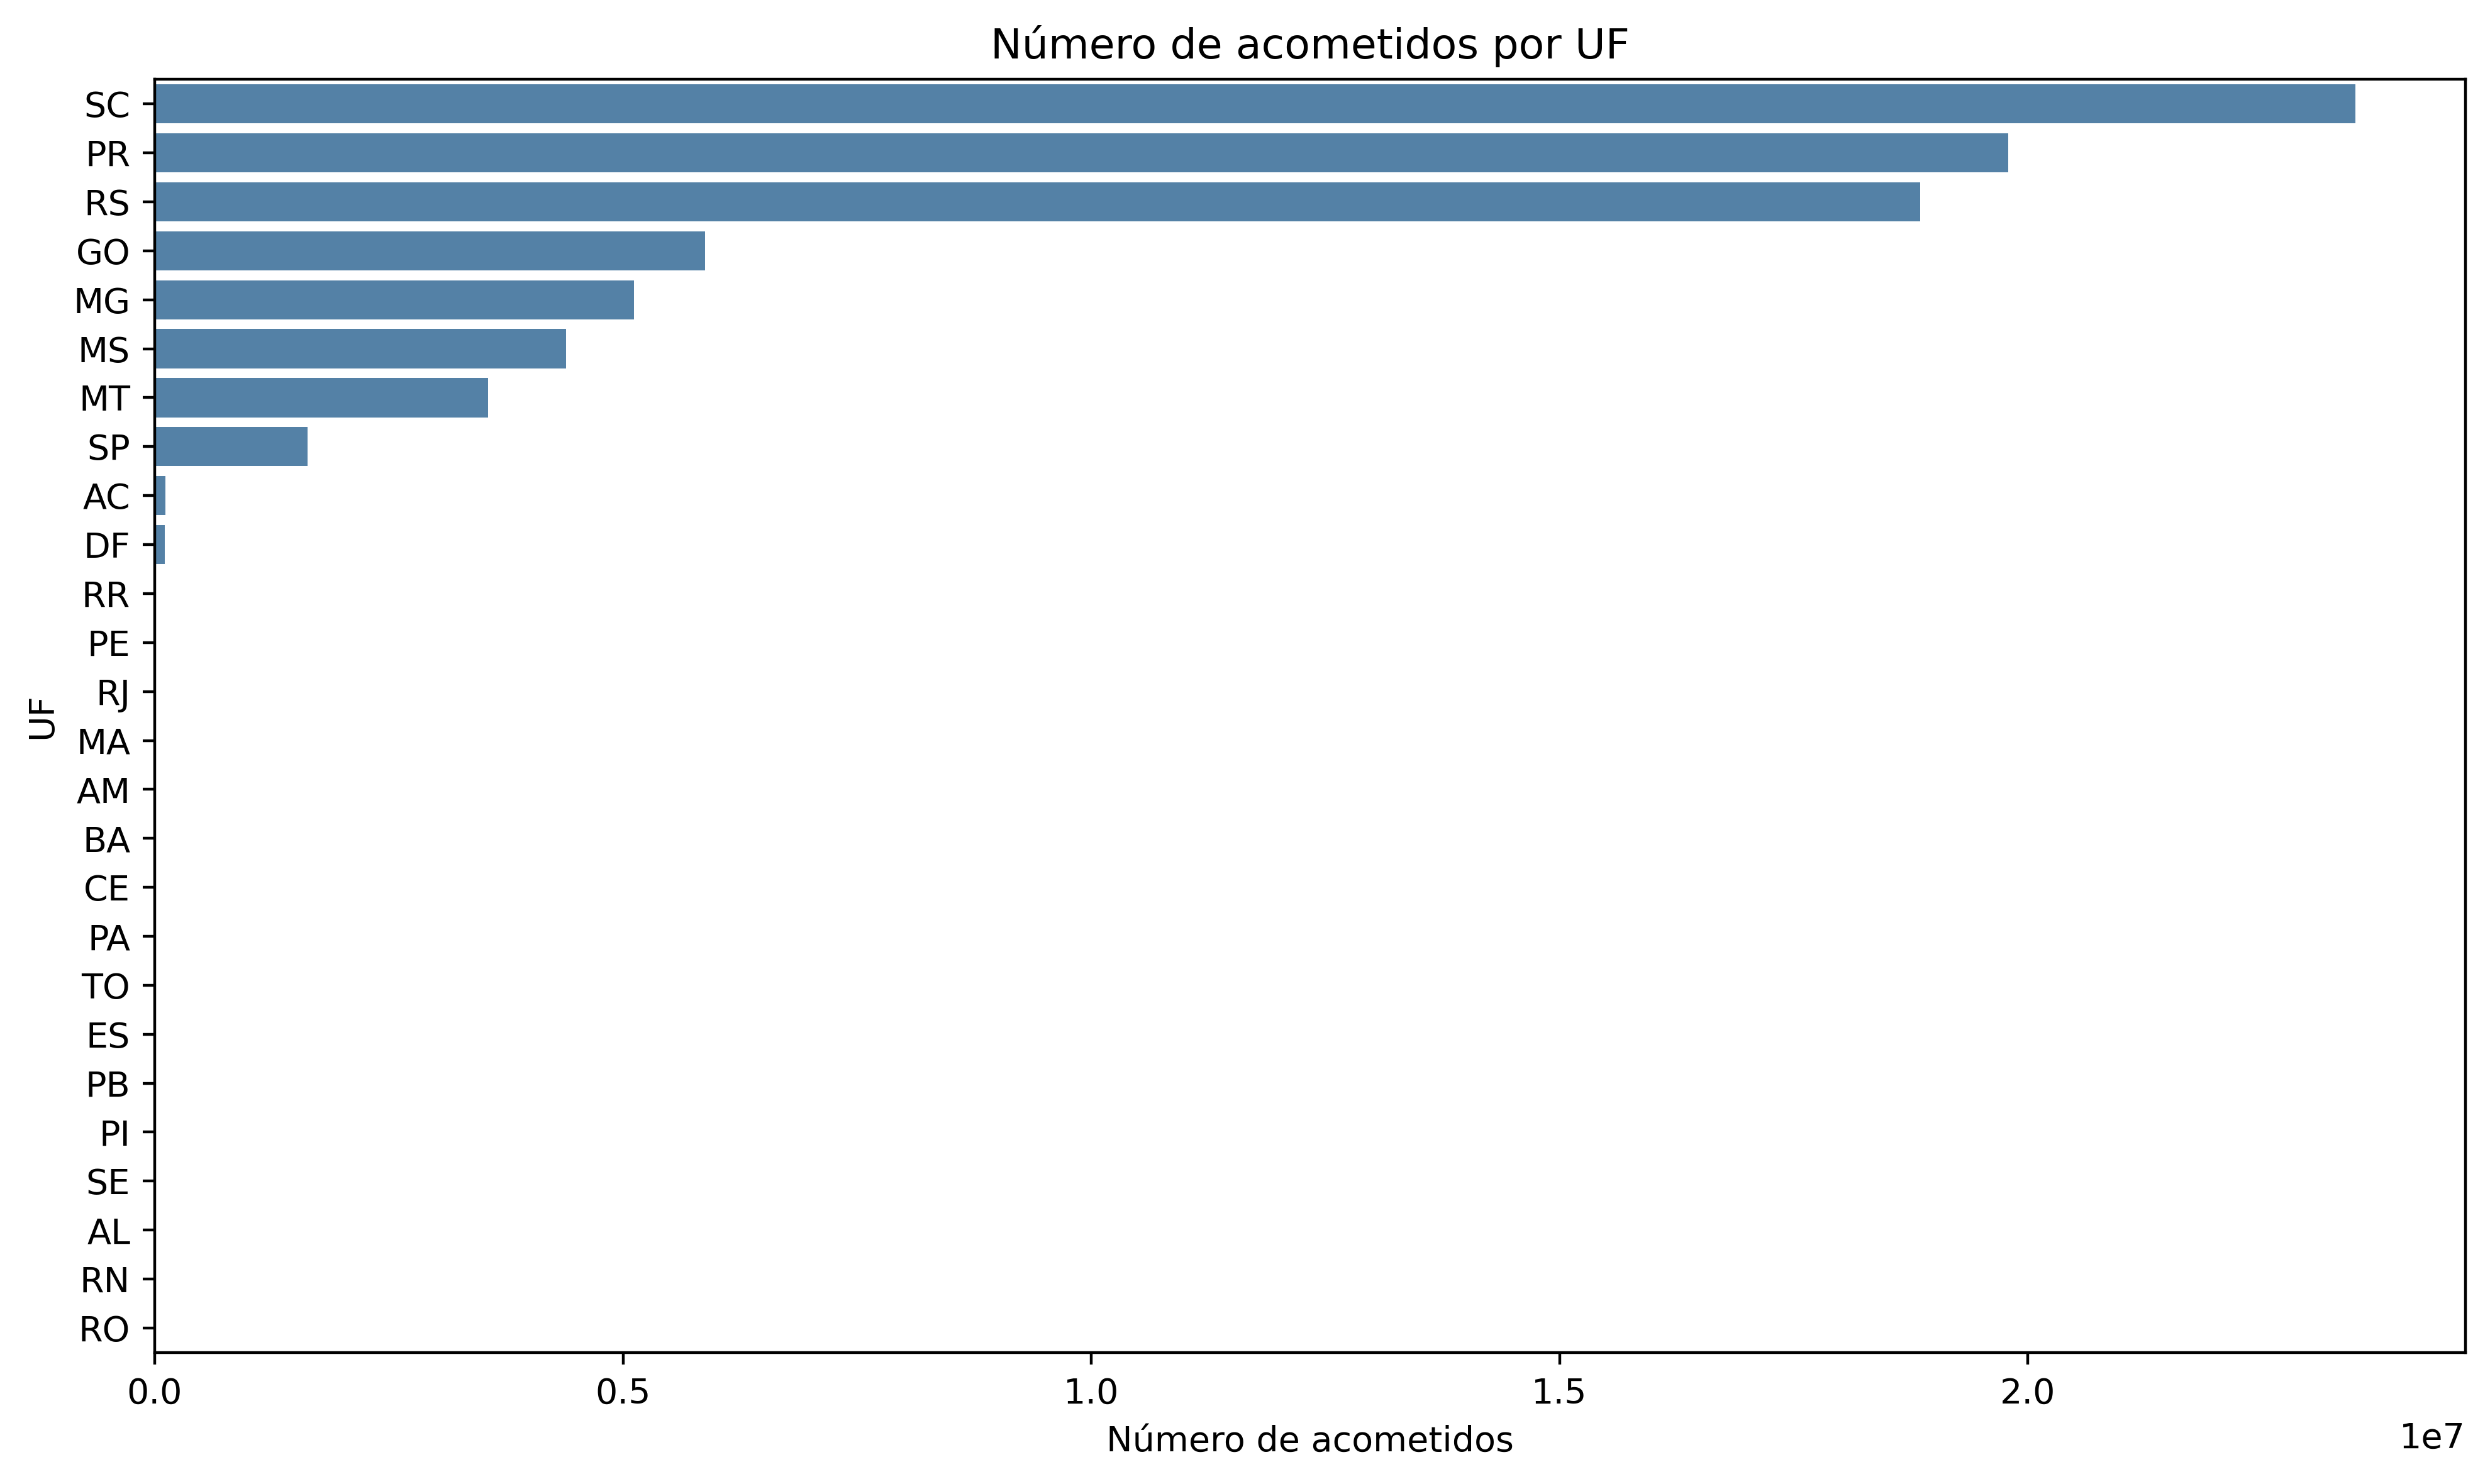

In [26]:
#realiza o ranking por estado de procedência
ranking_uf = (
    df_suino_doenças.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

pl.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [27]:
#criando a tabela cruzada entre estado de procedência e diagnóstico
tabela_uf_diagnostico = pd.pivot_table(
    df_suino_doenças,
    values="NUMERO_ANIMAIS_ACOMETIDOS",
    index="UF_PROCEDENCIA",
    columns="DIAGNOSTICO",
    aggfunc="sum",
    fill_value=0
)

tabela_uf_diagnostico

DIAGNOSTICO,aborto recente (fêmea),abscesso,abscesso (mamíferos),adenite,aderencias,aderência de pleura (purulenta),aderência de pleura (seca),aderência de pleura (úmida),adipoxantose,agalaxia contagiosa (notificação sif),...,síndrome nervosa (suspeito),síndrome vesicular (descartada pelo svo),síndrome vesicular (suspeito),teleangiectasia maculosa,tuberculose (já notificado),tuberculose (notificação sif),tuberculose (reagente já notificado),urticaria,verminose,útero com feto(s)
UF_PROCEDENCIA,,,,,,,,,,,,,,,,,,,,,
AC,0,0,113,0,0,6,3218,20,0,0,...,0,0,0,0,0,0,0,0,0,0
AL,0,0,0,0,0,1,5,4,0,0,...,0,0,0,0,0,0,0,0,0,0
AM,0,0,30,0,0,3,68,10,0,0,...,0,0,0,0,0,0,0,0,0,0
BA,0,0,25,0,0,3,10,2,0,0,...,0,0,0,0,0,0,0,0,0,0
CE,0,0,48,0,0,5,189,9,0,0,...,0,0,0,0,0,0,0,0,0,0
DF,0,0,424,0,0,11,212,17,0,0,...,0,0,170,0,0,0,0,0,0,0
ES,0,2,17,0,0,1,55,3,0,0,...,0,0,0,0,0,0,0,0,0,0
GO,0,2,17114,0,3,19003,124403,4597,0,0,...,0,3,796,0,0,0,0,0,0,0
MA,0,0,59,0,0,8,128,62,0,0,...,0,0,0,0,0,0,0,0,0,0


In [28]:
#Analisando o ranking por estado de procedência
ranking_uf = (
    df_suino_doenças.groupby("UF_PROCEDENCIA", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS
22,SC,23499489
16,PR,19793695
21,RS,18849001
7,GO,5875808
9,MG,5119785
10,MS,4388317
11,MT,3559044
24,SP,1631317
0,AC,116201
5,DF,105868


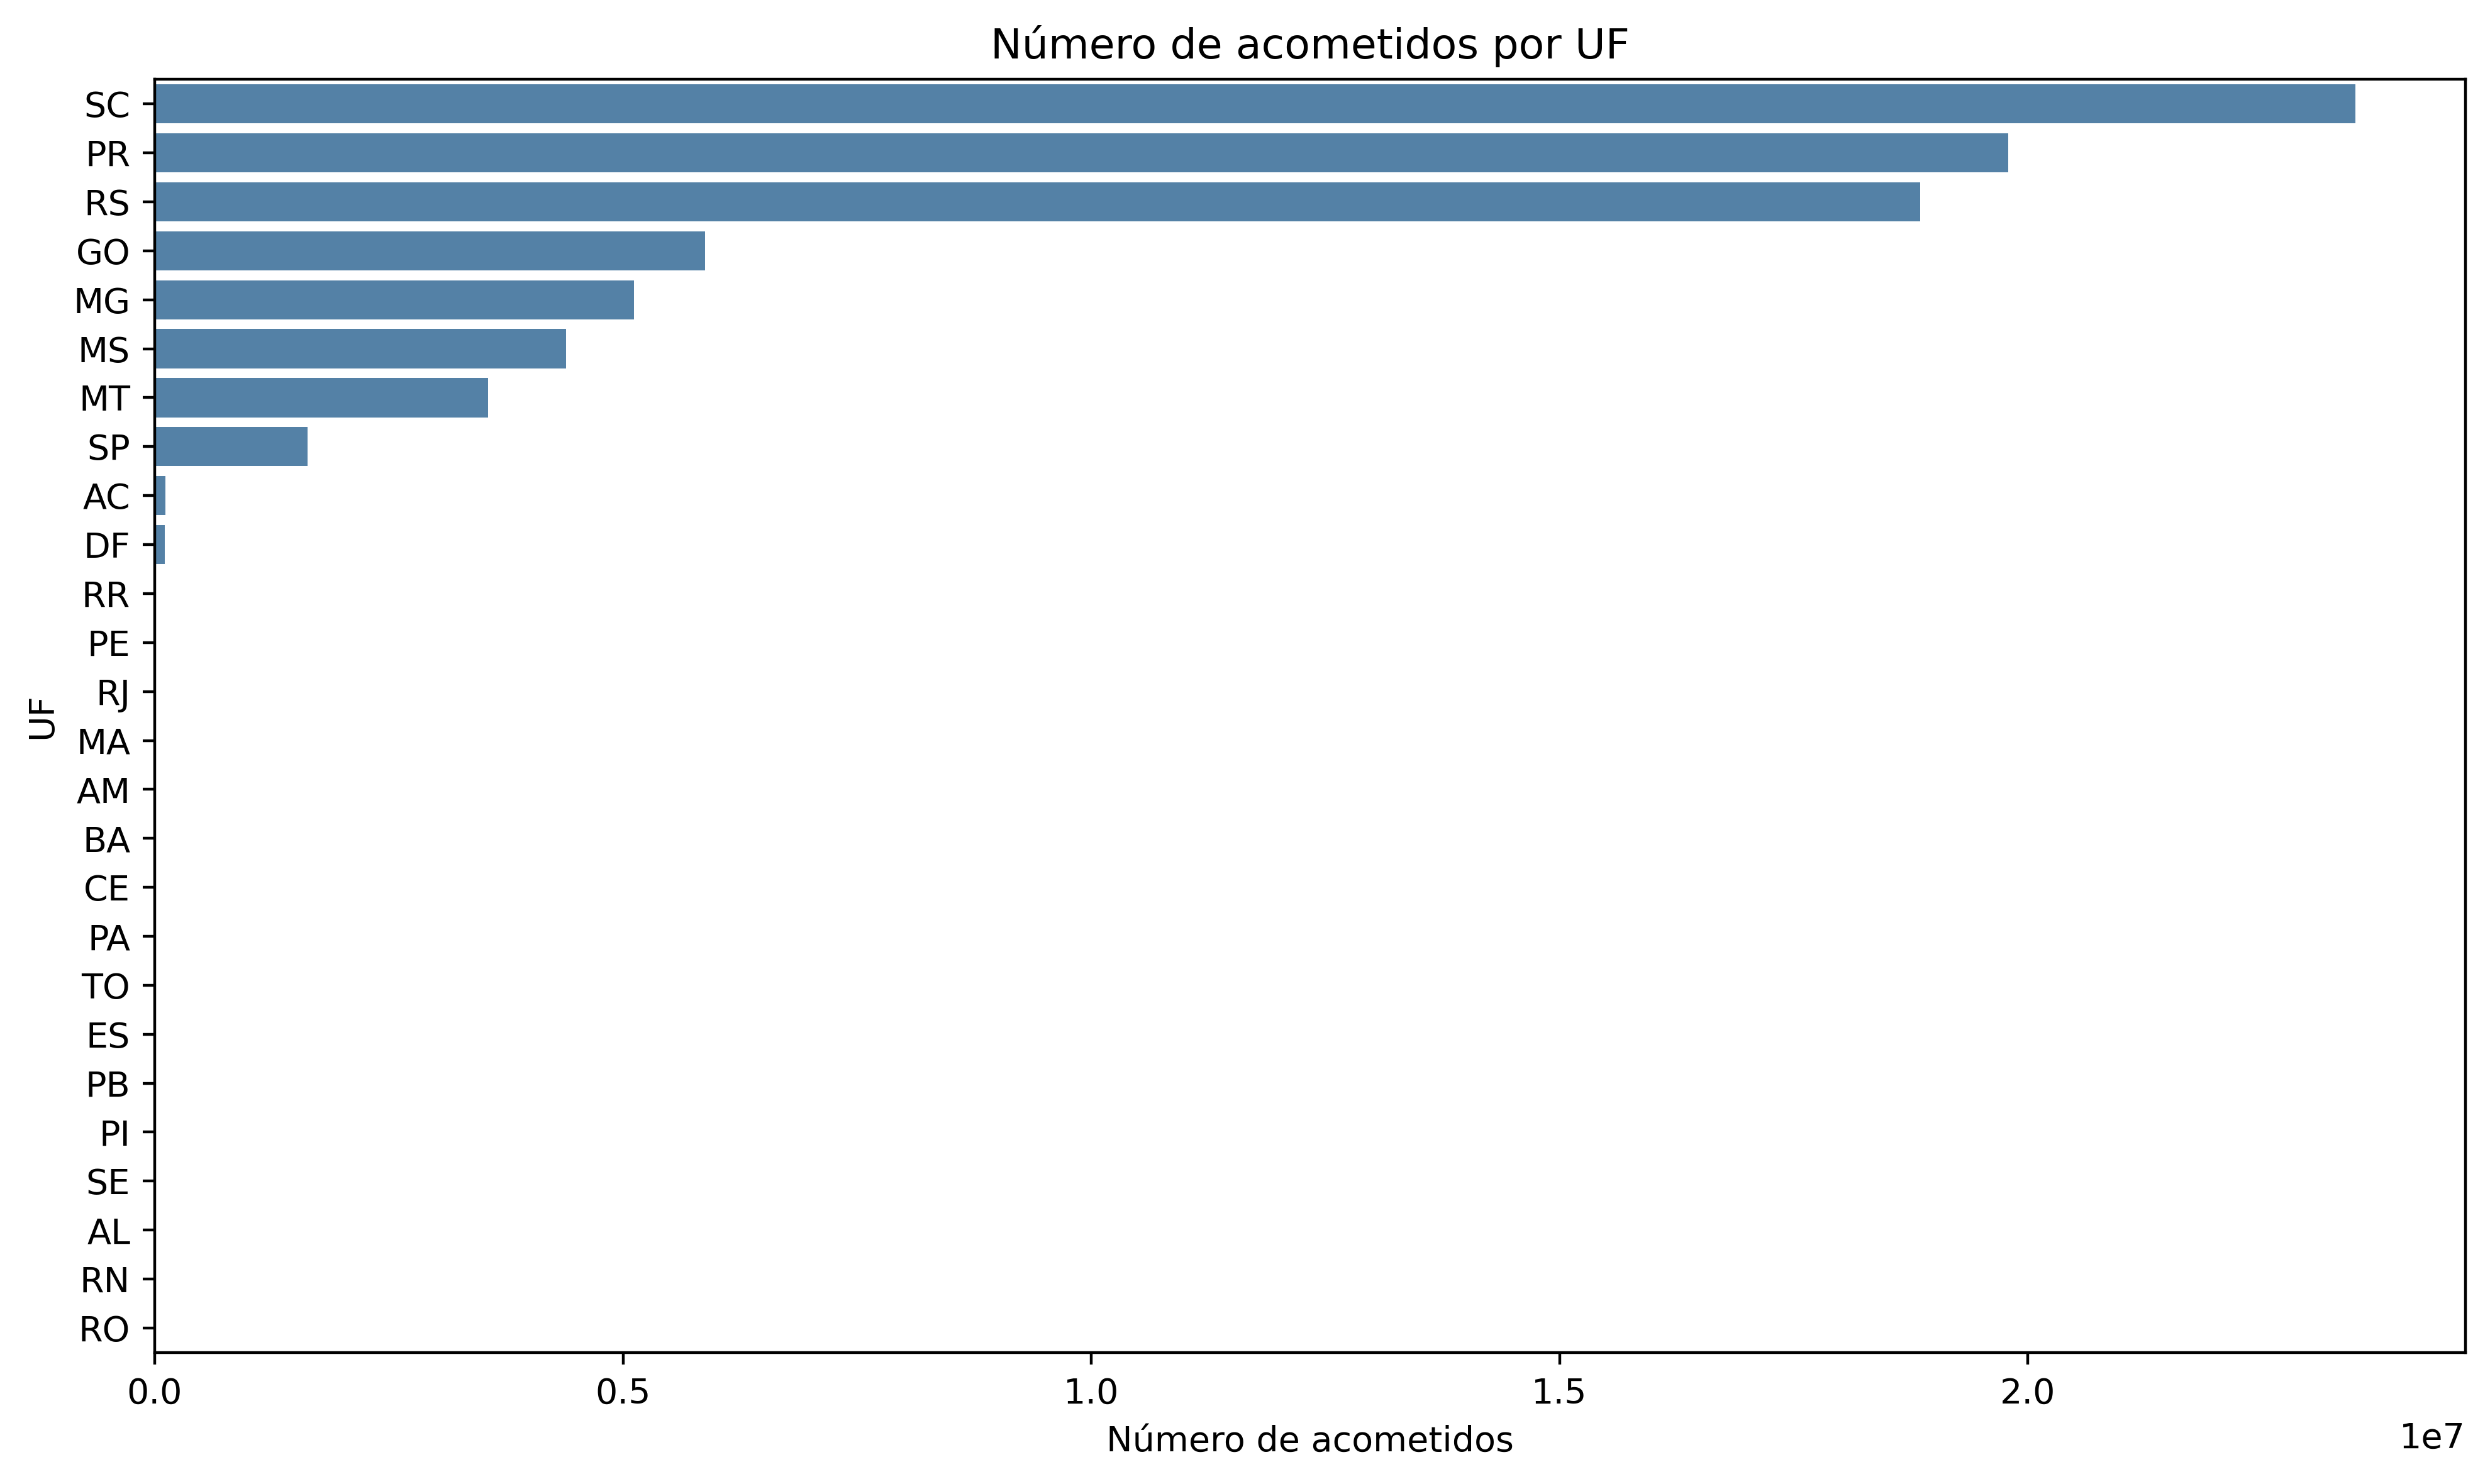

In [29]:
#Criando o gráfico de barras do número de acometidos por UF
pl.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_uf,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="UF_PROCEDENCIA",
    color="steelblue"
)

pl.title("Número de acometidos por UF")
pl.xlabel("Número de acometidos")
pl.ylabel("UF")
pl.tight_layout()
pl.show()

In [30]:
ranking_uf["percentual"] = (
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_uf["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_uf

,UF_PROCEDENCIA,NUMERO_ANIMAIS_ACOMETIDOS,percentual
22,SC,23499489,28
16,PR,19793695,24
21,RS,18849001,23
7,GO,5875808,7
9,MG,5119785,6
10,MS,4388317,5
11,MT,3559044,4
24,SP,1631317,2
0,AC,116201,0
5,DF,105868,0


In [31]:
ranking_diagnostico = (
    df_suino_doenças.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
11,alteração restrita,41599696
44,contaminação gastrointestinal e biliar,22849185
45,contaminação não gastrointestinal,4684108
6,aderência de pleura (seca),2534376
142,sêneca vírus (confirmado),2072571
...,...,...
33,carnes sanguinolentas,1
52,dermatose nodular contagiosa (suspeito),1
130,pleuropneumonia contagiosa,1
122,onfaloflebite,1


In [32]:
ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico

,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual
11,alteração restrita,41599696,50
44,contaminação gastrointestinal e biliar,22849185,28
45,contaminação não gastrointestinal,4684108,6
6,aderência de pleura (seca),2534376,3
142,sêneca vírus (confirmado),2072571,2
...,...,...,...
33,carnes sanguinolentas,1,0
52,dermatose nodular contagiosa (suspeito),1,0
130,pleuropneumonia contagiosa,1,0
122,onfaloflebite,1,0


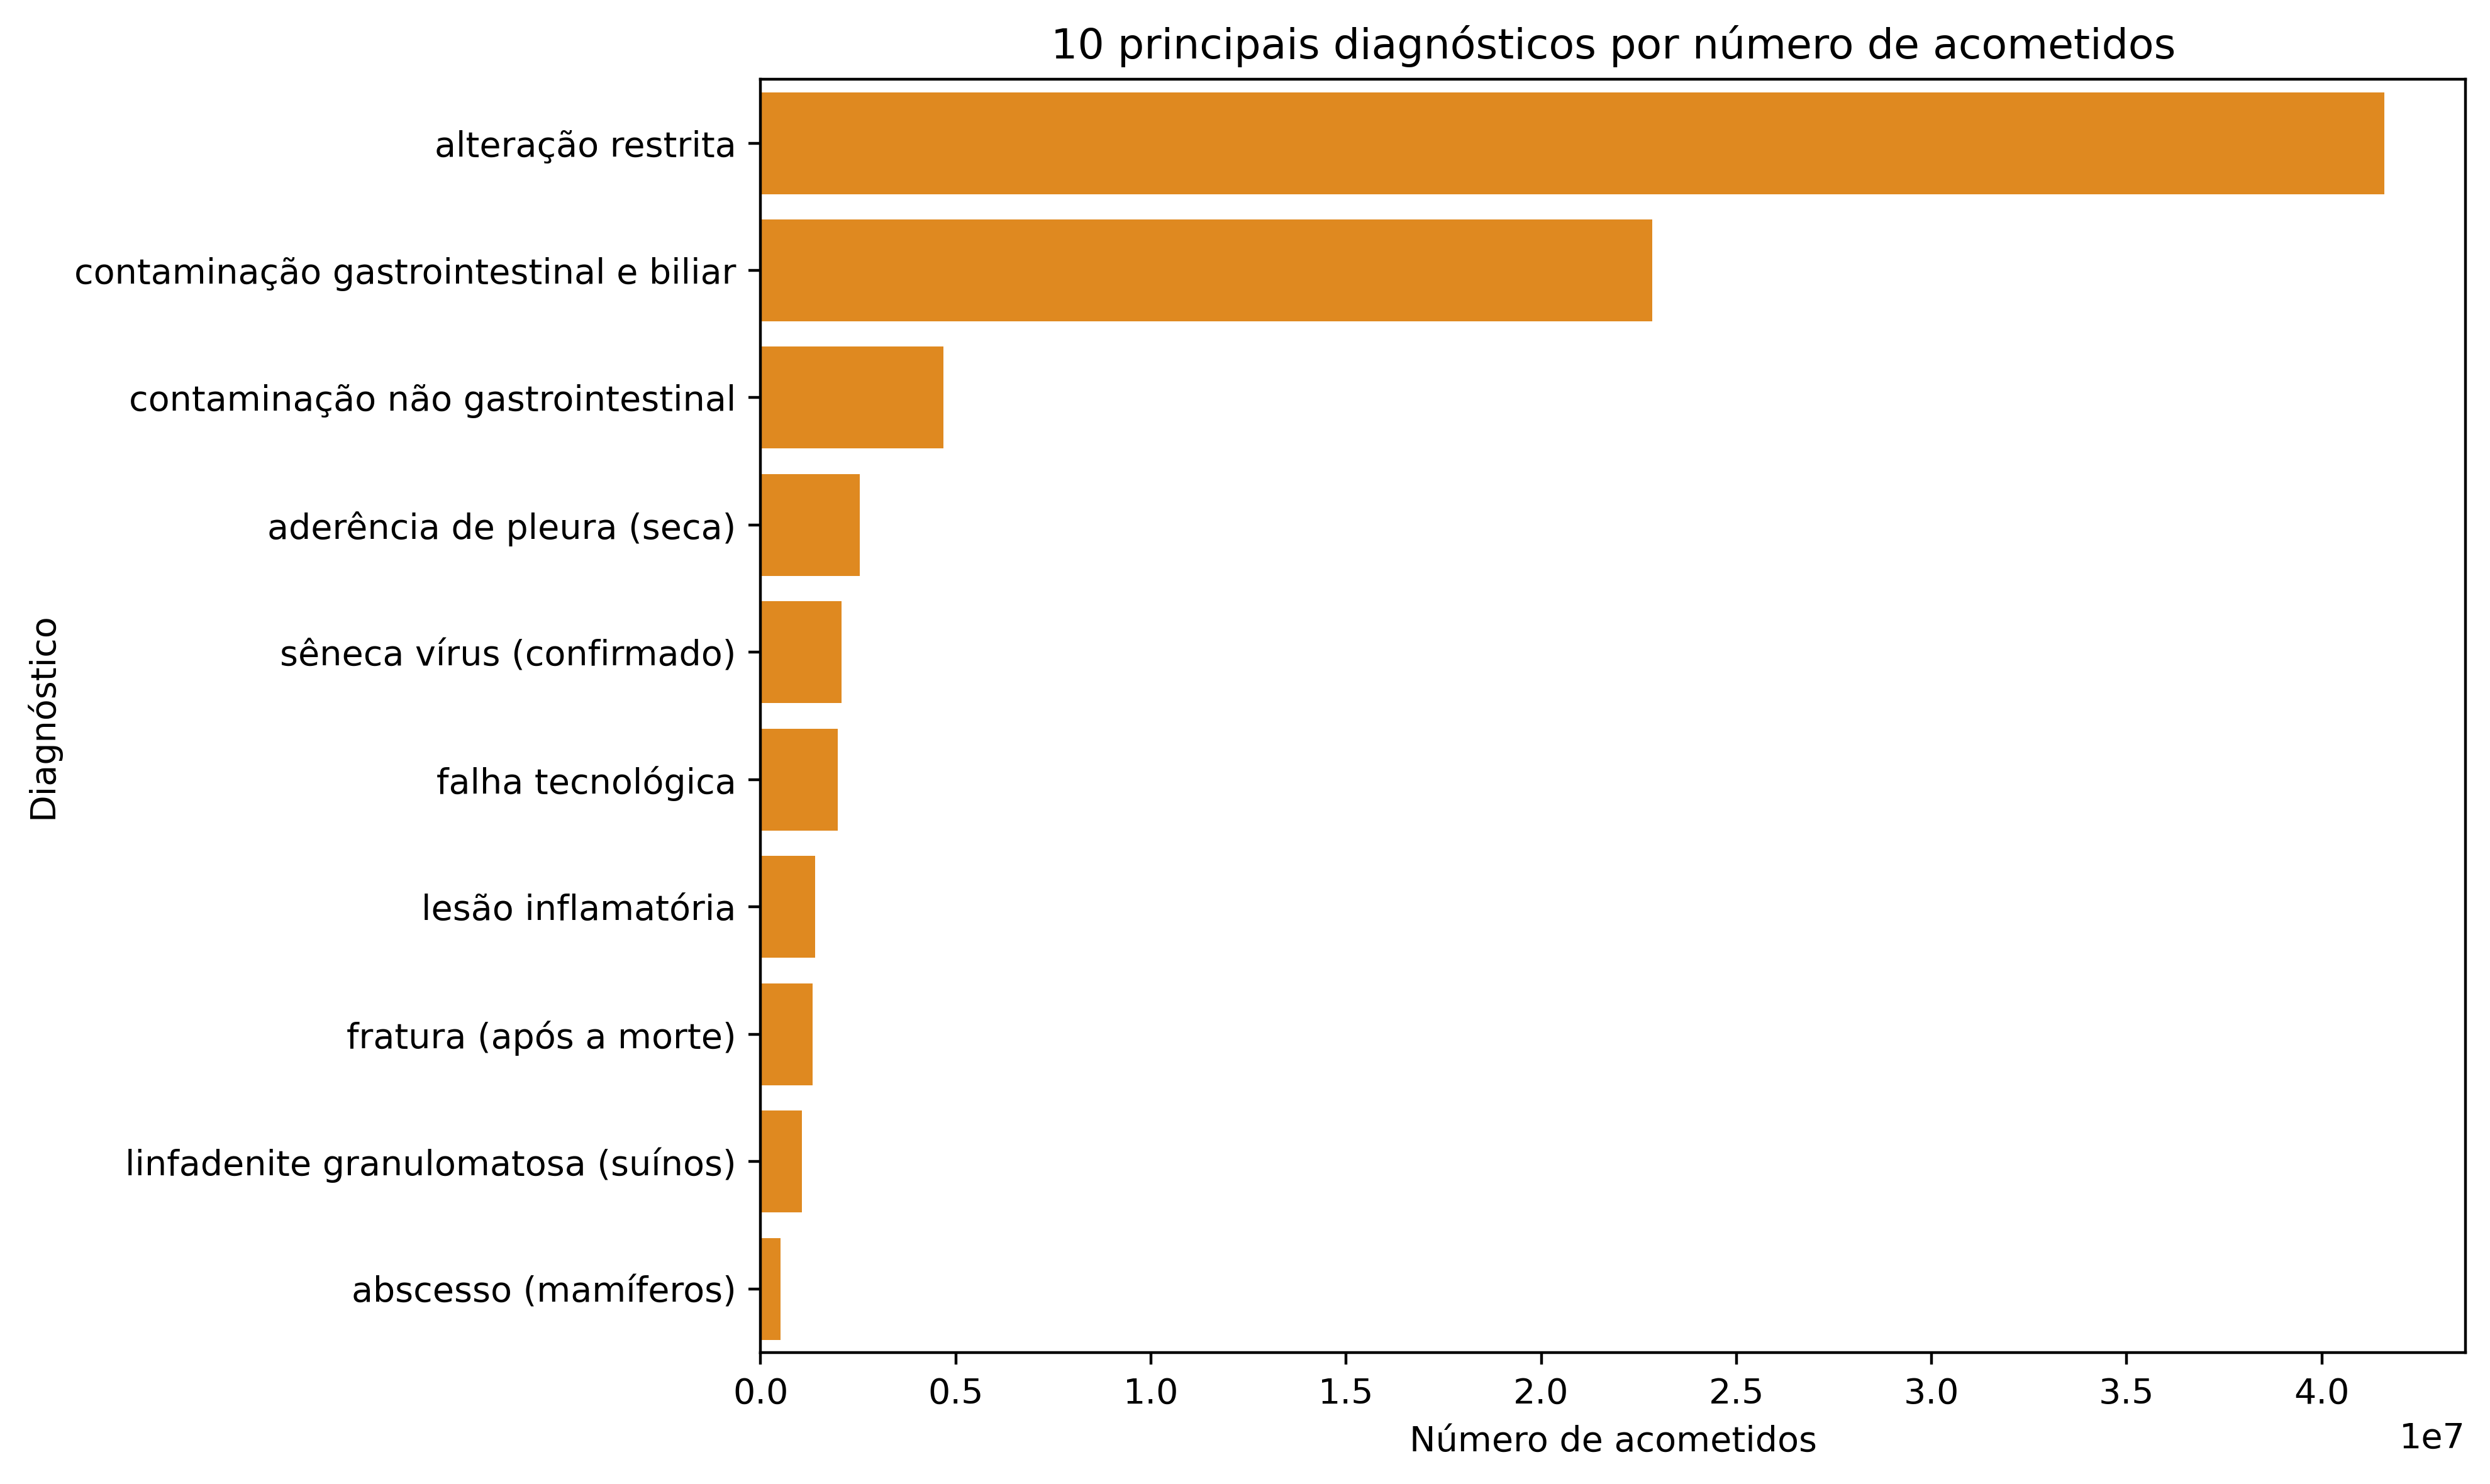

In [33]:
top10_diagnostico = ranking_diagnostico.head(10)

pl.figure(figsize=(10, 6))

sns.barplot(
    data=top10_diagnostico,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    y="DIAGNOSTICO",
    color="darkorange"
)

pl.title("10 principais diagnósticos por número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Diagnóstico")
pl.tight_layout()
pl.show()

In [34]:
diagnostico_ano = (
    df_suino_doenças.groupby(["ANO", "DIAGNOSTICO"], as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(["ANO", "NUMERO_ANIMAIS_ACOMETIDOS"], ascending=[True, False])
)

diagnostico_ano

,ANO,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS
11,2021,alteração restrita,7273239
42,2021,contaminação gastrointestinal e biliar,3500226
43,2021,contaminação não gastrointestinal,841760
86,2021,lesão inflamatória,692549
6,2021,aderência de pleura (seca),545765
...,...,...,...
469,2026,cisticercose suína (notificação sif),2
494,2026,linfadenite caseosa (já notificado),2
468,2026,castração inadequada (suíno),1
484,2026,fígado amarelo,1


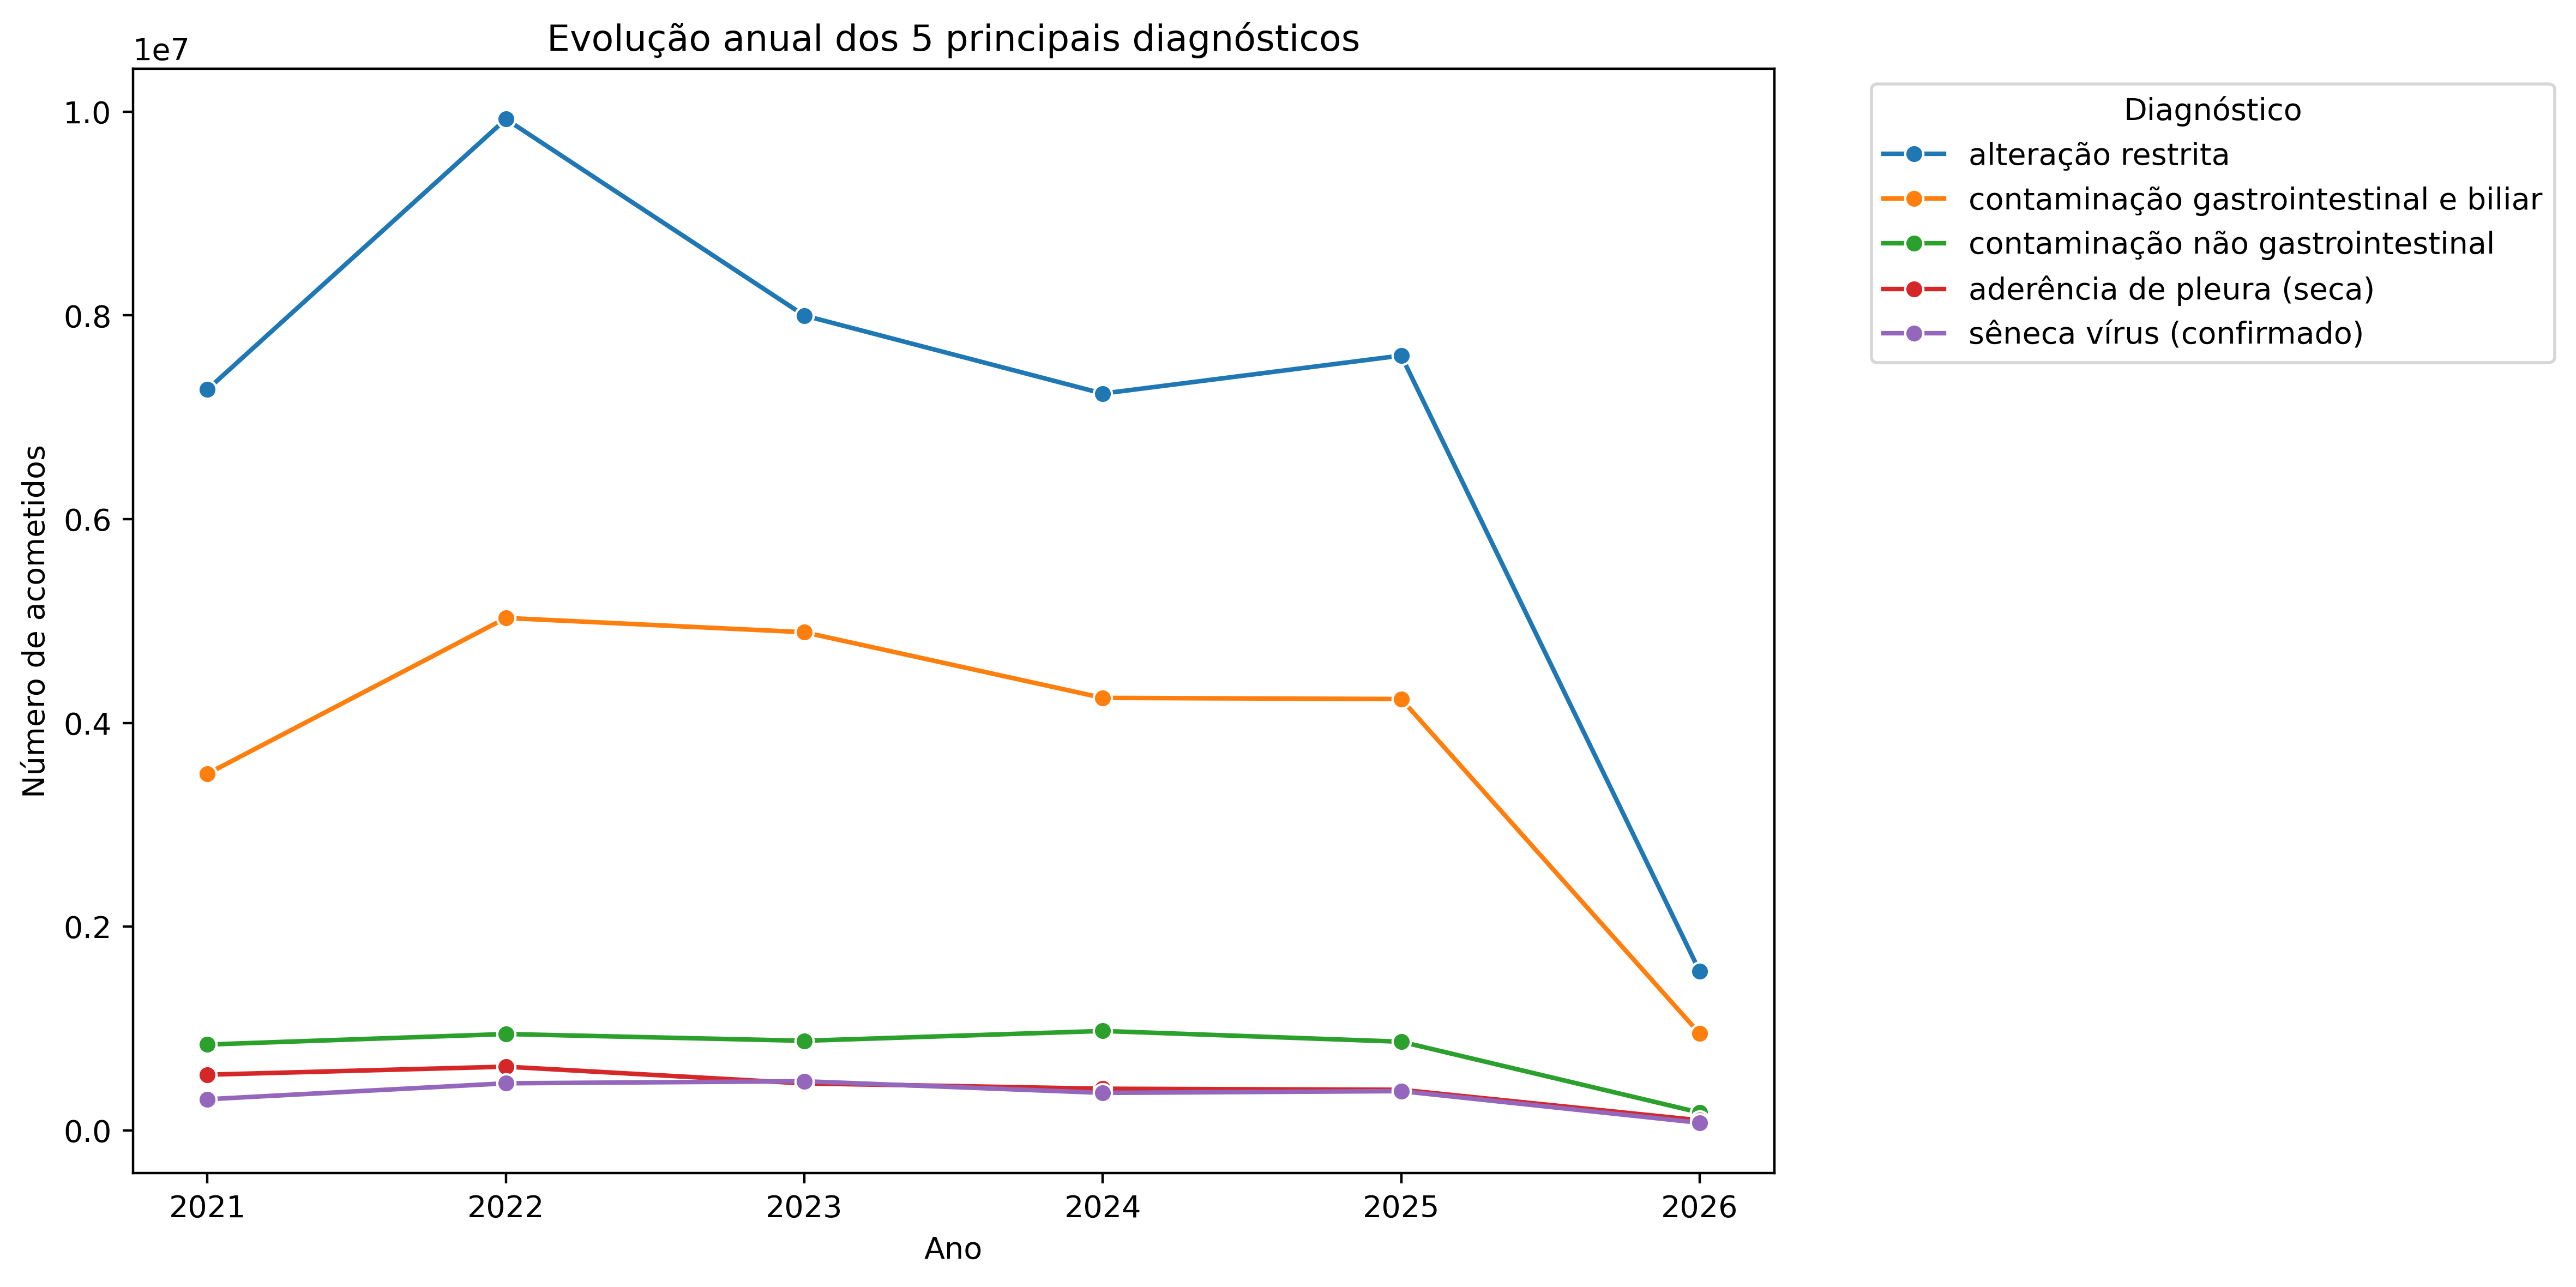

In [35]:
top5_diag = (
    df_suino_doenças.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

diagnostico_ano_top5 = diagnostico_ano[
    diagnostico_ano["DIAGNOSTICO"].isin(top5_diag)
]

pl.figure(figsize=(12, 6))

sns.lineplot(
    data=diagnostico_ano_top5,
    x="ANO",
    y="NUMERO_ANIMAIS_ACOMETIDOS",
    hue="DIAGNOSTICO",
    marker="o"
)

pl.title("Evolução anual dos 5 principais diagnósticos")
pl.xlabel("Ano")
pl.ylabel("Número de acometidos")
pl.xticks(sorted(diagnostico_ano_top5["ANO"].unique()))
pl.legend(title="Diagnóstico", bbox_to_anchor=(1.05, 1), loc="upper left")
pl.tight_layout()
pl.show()

In [36]:
media = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].mean()
mediana = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].median()
desvio_padrao = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].std()
variancia = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].var()
coef_variacao = desvio_padrao / media * 100
print(f"Média: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrão: {desvio_padrao:.2f}")
print(f"Variância: {variancia:.2f}")
print(f"Coeficiente de Variação: {coef_variacao:.2f}%")

Média: 3571.39
Mediana: 32.00
Desvio Padrão: 19252.73
Variância: 370667775.57
Coeficiente de Variação: 539.08%


In [37]:
assimetria = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].skew()
curtose = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].kurtosis()
print(f"Assimetria: {assimetria:.2f}")
print(f"Curtose: {curtose:.2f}")

Assimetria: 8.72
Curtose: 88.08


In [38]:
minimo = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].min()
maximo = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].max()
amplitude = maximo - minimo

q1 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
iqr = q3 - q1
print(f"Valor mínimo: {minimo}")
print(f"Valor máximo: {maximo}")
print(f"Amplitude: {amplitude}")
print(f"Q1: {q1}")
print(f"Q3: {q3}")
print(f"IQR: {iqr}")

Valor mínimo: 1
Valor máximo: 327643
Amplitude: 327642
Q1: 5.0
Q3: 316.0
IQR: 311.0


In [39]:
q1 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.25)
q3 = df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"].quantile(0.75)
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers = df_suino_doenças[
    (df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"] < limite_inferior) |
    (df_suino_doenças["NUMERO_ANIMAIS_ACOMETIDOS"] > limite_superior)
]

print(f"Outliers encontrados:\n{outliers}")

Outliers encontrados:
          MES_ANO UF_PROCEDENCIA ESPECIE                        DIAGNOSTICO  \
9011   2023-02-01             DF   Suíno                 alteração restrita   
91950  2023-03-01             RS   Suíno                         septicemia   
106100 2024-04-01             MG   Suíno         aderência de pleura (seca)   
141654 2026-03-01             SP   Suíno  contaminação não gastrointestinal   
835    2023-10-01             GO   Suíno  contaminação não gastrointestinal   
...           ...            ...     ...                                ...   
29078  2022-06-01             SC   Suíno                 alteração restrita   
126006 2021-09-01             SC   Suíno                 alteração restrita   
13138  2021-11-01             SC   Suíno                 alteração restrita   
194569 2022-05-01             SC   Suíno                 alteração restrita   
187189 2022-03-01             SC   Suíno                 alteração restrita   

        NUMERO_ANIMAIS_ACOMET

In [40]:
desc_por_uf = (
      df_suino_doenças.groupby("UF_PROCEDENCIA")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)

desc_por_uf


,count,sum,mean,median,std,min,max
UF_PROCEDENCIA,,,,,,,
SC,3040,23499489,7730,58,32848,1,327643
PR,2986,19793695,6629,59,28936,1,245389
RS,2898,18849001,6504,74,27163,1,218550
GO,1994,5875808,2947,45,9337,1,76161
MG,2580,5119785,1984,26,7396,1,67356
MS,2076,4388317,2114,55,7088,1,59387
MT,2109,3559044,1688,36,6022,1,49567
SP,1991,1631317,819,17,3160,1,25897
AC,867,116201,134,10,316,1,1840


In [41]:
desc_por_diagnostico = (
    df_suino_doenças.groupby("DIAGNOSTICO")["NUMERO_ANIMAIS_ACOMETIDOS"]
      .agg(["count", "sum", "mean", "median", "std", "min", "max"])
      .sort_values("sum", ascending=False)
)
desc_por_diagnostico

,count,sum,mean,median,std,min,max
DIAGNOSTICO,,,,,,,
alteração restrita,834,41599696,49880,17860,72897,1,327643
contaminação gastrointestinal e biliar,836,22849185,27332,6542,42531,1,198626
contaminação não gastrointestinal,705,4684108,6644,3380,9130,1,57794
aderência de pleura (seca),722,2534376,3510,1090,4894,1,28156
sêneca vírus (confirmado),66,2072571,31403,32926,15185,116,75744
...,...,...,...,...,...,...,...
carnes sanguinolentas,1,1,1,1,NaN,1,1
dermatose nodular contagiosa (suspeito),1,1,1,1,NaN,1,1
pleuropneumonia contagiosa,1,1,1,1,NaN,1,1


In [42]:
ranking_diagnostico = (
    df_suino_doenças.groupby("DIAGNOSTICO", as_index=False)["NUMERO_ANIMAIS_ACOMETIDOS"]
      .sum()
      .sort_values("NUMERO_ANIMAIS_ACOMETIDOS", ascending=False)
)

ranking_diagnostico["percentual"] = (
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"] /
    ranking_diagnostico["NUMERO_ANIMAIS_ACOMETIDOS"].sum() * 100
)

ranking_diagnostico["percentual_acumulado"] = ranking_diagnostico["percentual"].cumsum()

ranking_diagnostico


,DIAGNOSTICO,NUMERO_ANIMAIS_ACOMETIDOS,percentual,percentual_acumulado
11,alteração restrita,41599696,50,50
44,contaminação gastrointestinal e biliar,22849185,28,78
45,contaminação não gastrointestinal,4684108,6,83
6,aderência de pleura (seca),2534376,3,86
142,sêneca vírus (confirmado),2072571,2,89
...,...,...,...,...
33,carnes sanguinolentas,1,0,100
52,dermatose nodular contagiosa (suspeito),1,0,100
130,pleuropneumonia contagiosa,1,0,100
122,onfaloflebite,1,0,100


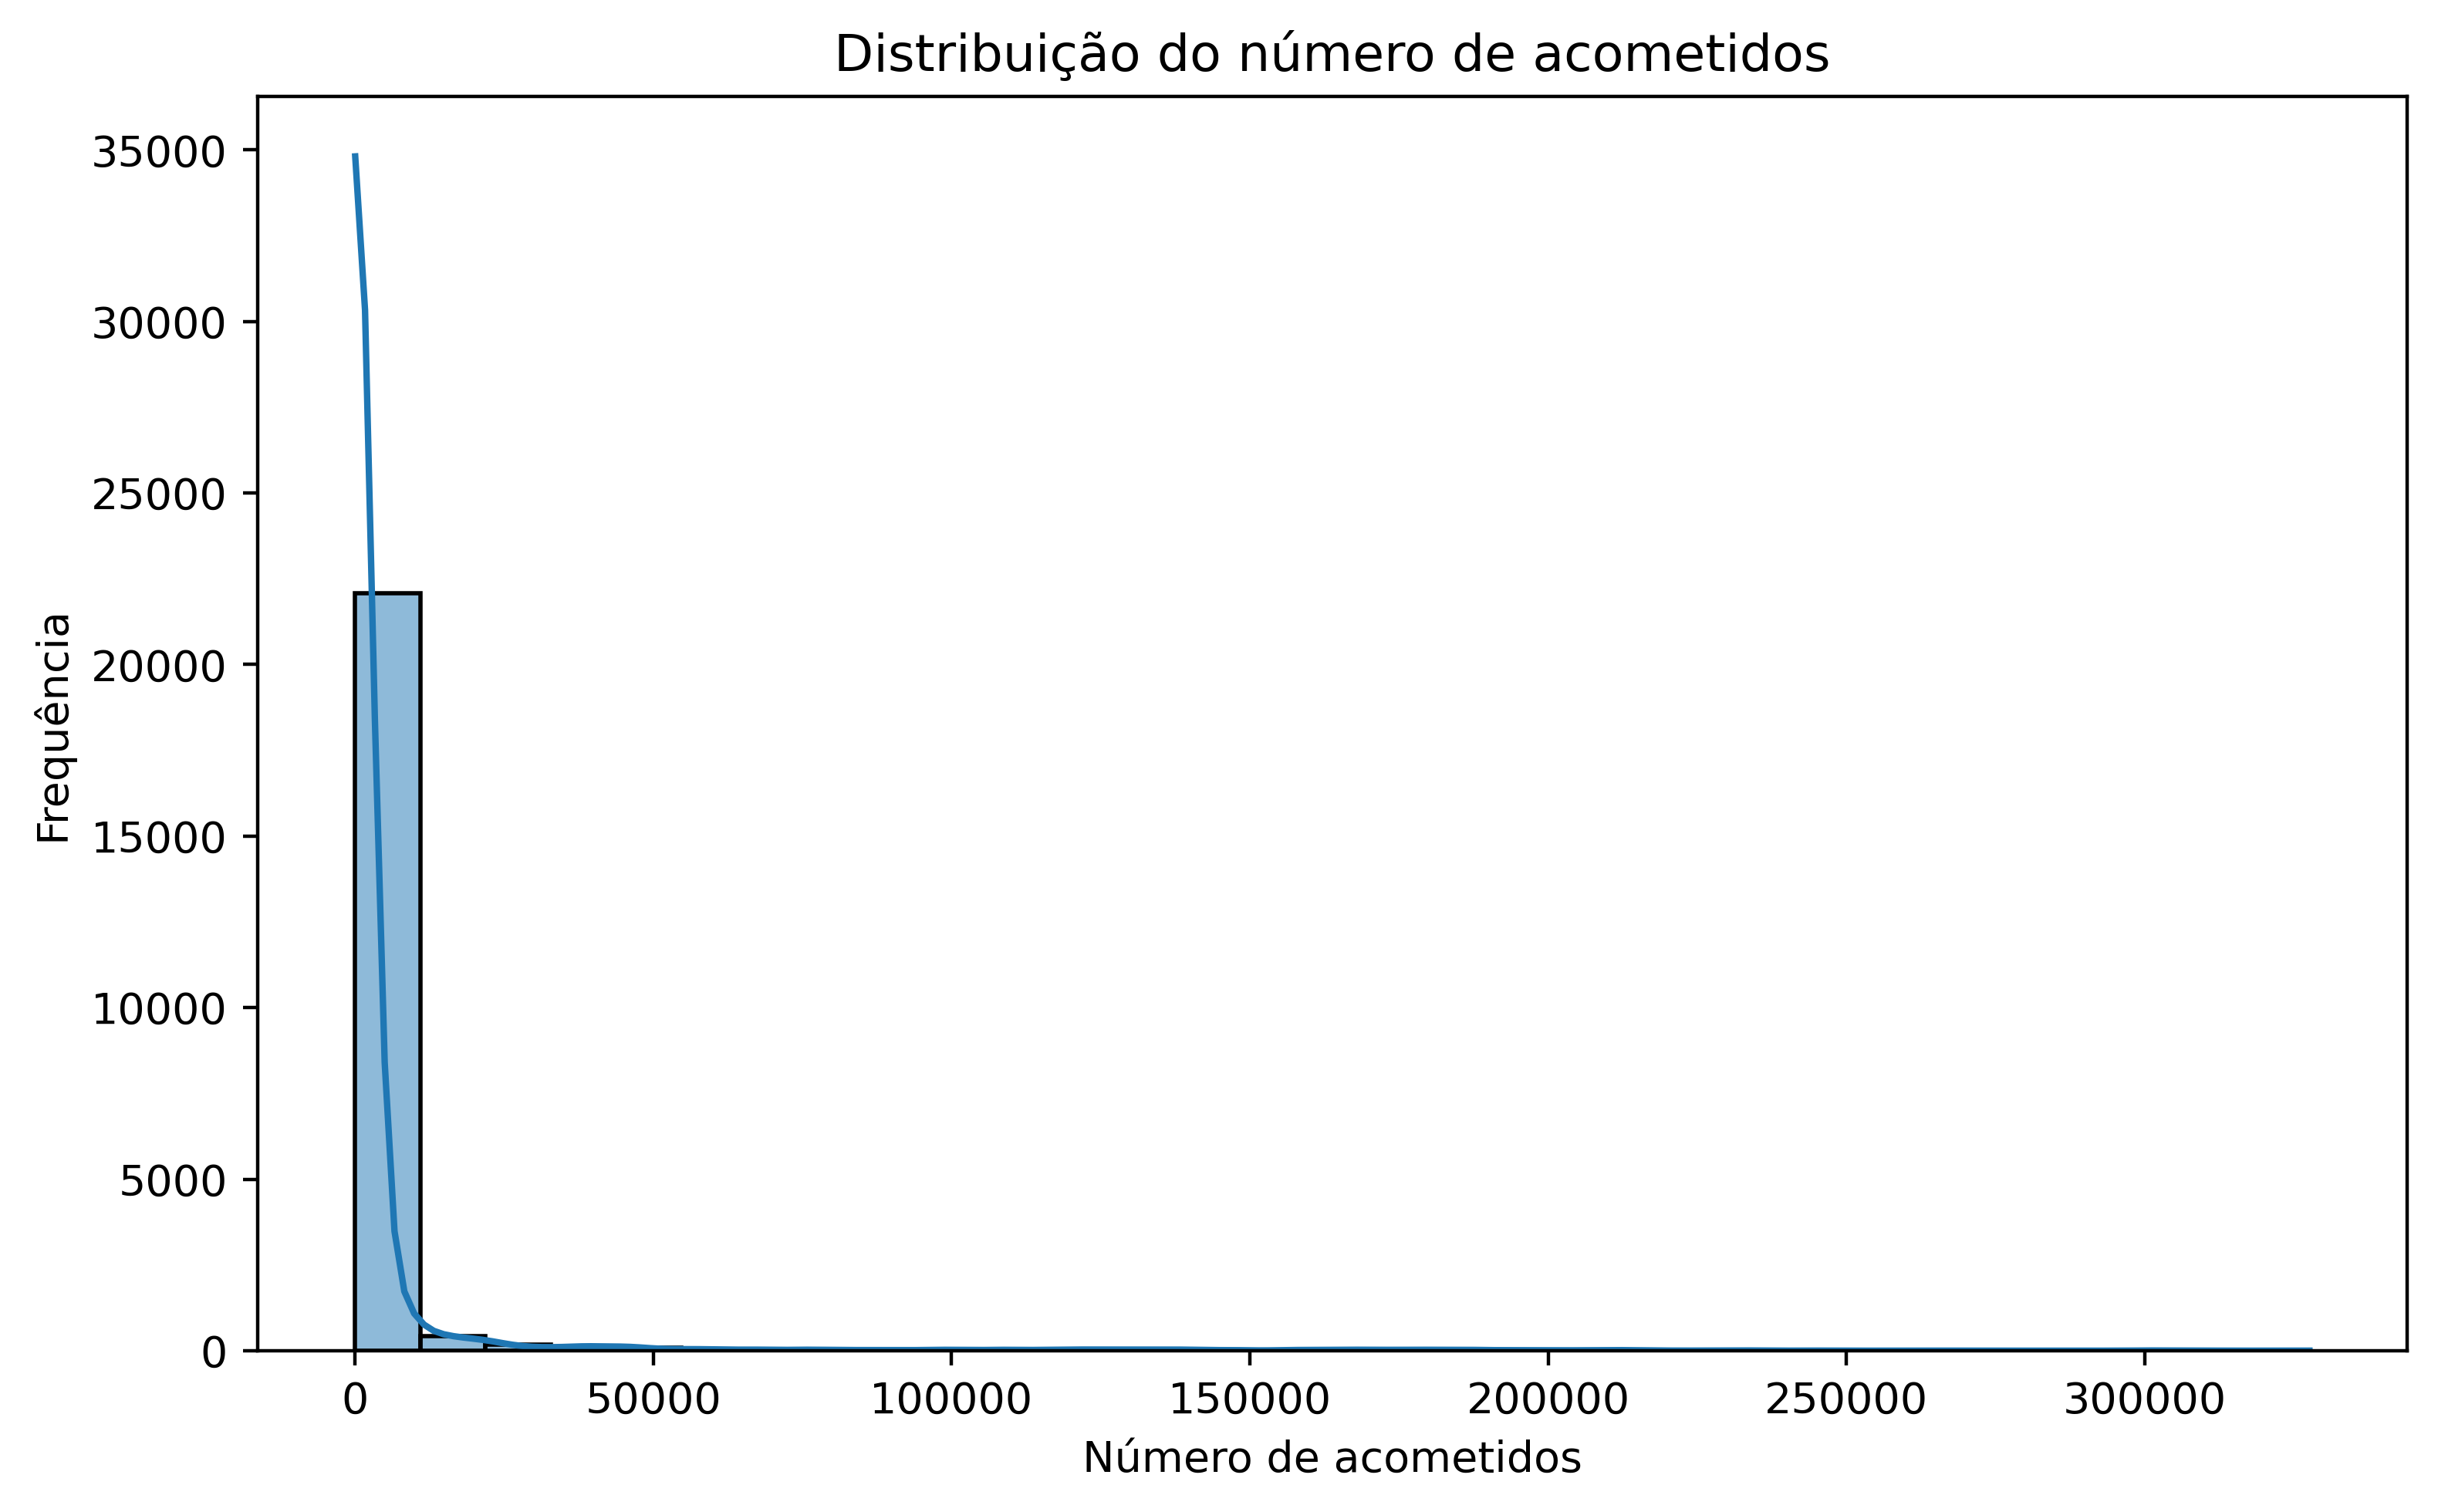

In [43]:
pl.figure(figsize=(8, 5))

sns.histplot(
    data=df_suino_doenças,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    bins=30,
    kde=True
)

pl.title("Distribuição do número de acometidos")
pl.xlabel("Número de acometidos")
pl.ylabel("Frequência")
pl.tight_layout()
pl.show()


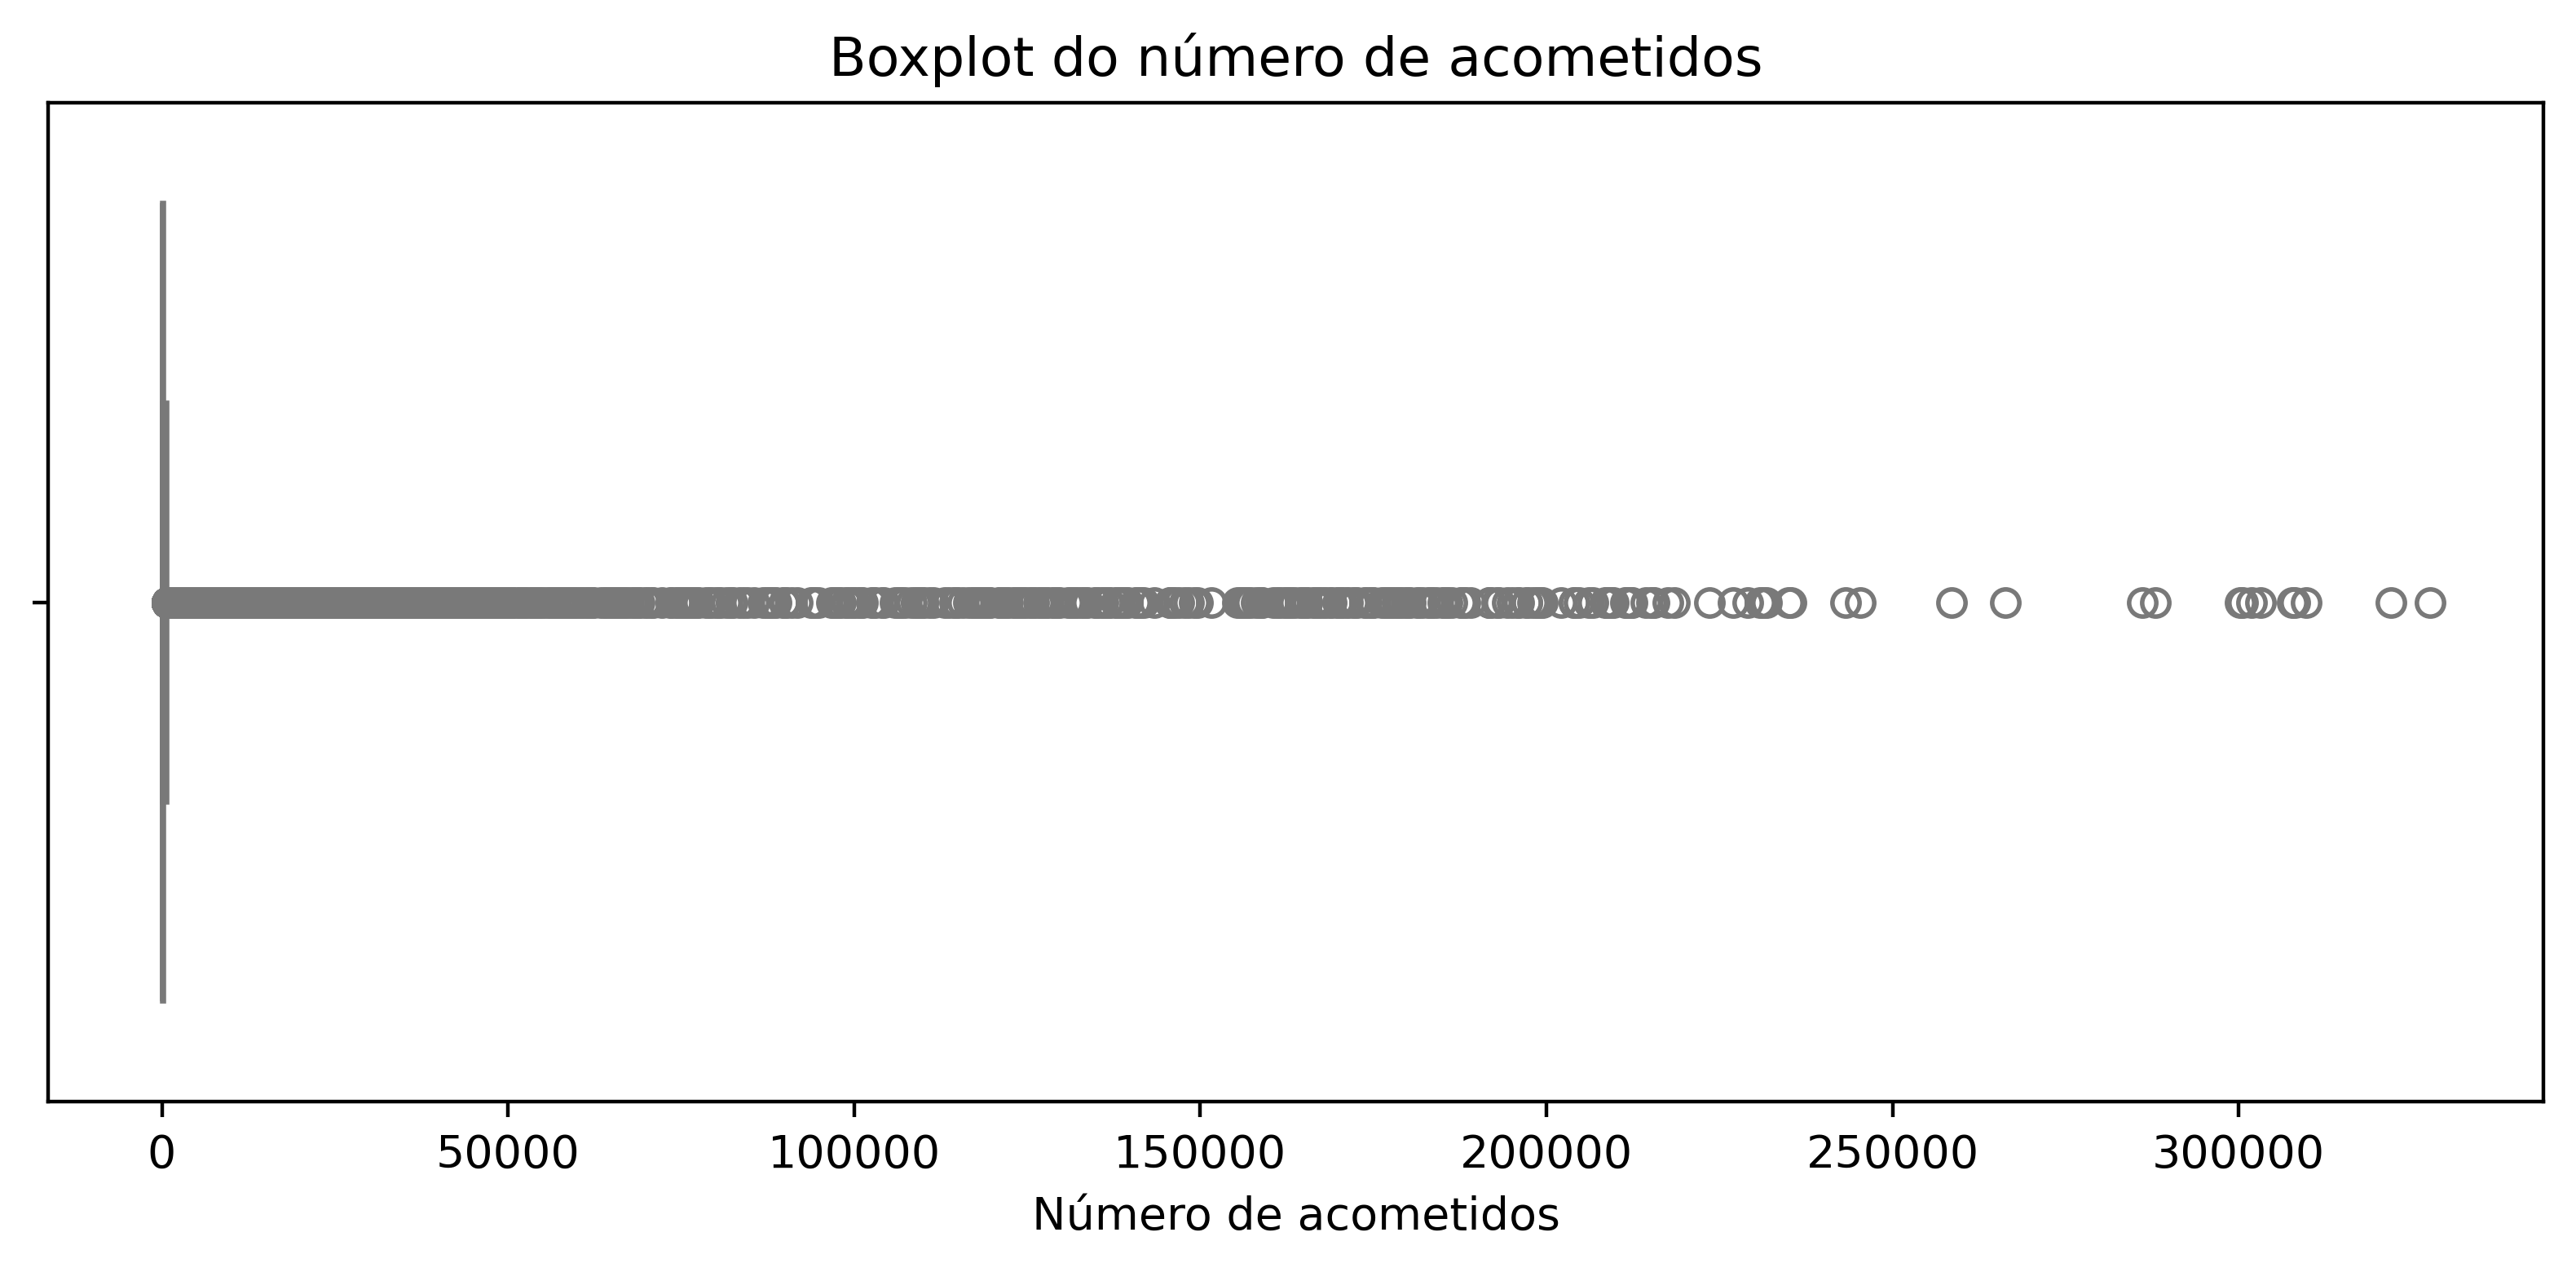

In [44]:
pl.figure(figsize=(8, 4))

sns.boxplot(
    data=df_suino_doenças,
    x="NUMERO_ANIMAIS_ACOMETIDOS",
    color="lightblue"
)

pl.title("Boxplot do número de acometidos")
pl.xlabel("Número de acometidos")
pl.tight_layout()
pl.show()
